# **NLP Pipeline for Customer Feedback Intelligence and Sentiment-Driven Decision Support**

**Project overview.** This notebook analyses 20,400 Trustpilot reviews of UK companies, a balanced random subset (3,400 per sector, fixed seed) of the 33,046 reviews in six sectors of the full Trustpilot Reviews 123k collection of 123,181 reviews (Broughton, 2025a, Hugging Face). Each review has free text, a business `Category` (six sectors, 3,400 reviews each) and a 1-5 `Stars` rating. We predict the category (the main target) and a three-class sentiment derived from the stars.

We follow the five assignment tasks: preprocessing and exploration (Task 1), a classical baseline (Task 2), word embeddings and retrieval (Task 3), a fine-tuned transformer (Task 4), and risks and mitigation (Task 5).


---

# Task 1 — Preprocessing and Exploratory Analysis for Customer Feedback Inputs


## A. Setup

We install and import the libraries and fix the random seeds.


In [1]:
import importlib
import os
import subprocess
import sys
import warnings

warnings.filterwarnings("ignore")
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

CORE_PACKAGES = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "nltk": "nltk",
    "spacy": "spacy",
    "sklearn": "scikit-learn",
    "wordcloud": "wordcloud",
    "gensim": "gensim",
    "torch": "torch",
    "sentence_transformers": "sentence-transformers",
}

def ensure_package(import_name: str, pip_name: str) -> None:
    try:
        importlib.import_module(import_name)
    except ImportError:
        print(f"Installing {pip_name} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

for import_name, pip_name in CORE_PACKAGES.items():
    ensure_package(import_name, pip_name)

import copy
import hashlib
import importlib.metadata as importlib_metadata
import random
import re
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.sparse import csr_matrix, hstack
from wordcloud import WordCloud

import nltk
import spacy
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.base import clone
from sklearn.decomposition import NMF, PCA
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.svm import LinearSVC

import torch
from gensim.models import Word2Vec
from huggingface_hub import hf_hub_download
from sentence_transformers import SentenceTransformer
from torch.utils.data import DataLoader, Dataset
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    get_linear_schedule_with_warmup,
)

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)
pd.set_option("display.max_colwidth", 160)

def display_table(data, title: str = None) -> None:
    if title:
        print(title)
    display(data)

def report_tables(y_true, y_pred, labels, name) -> None:
    report = classification_report(y_true, y_pred, labels=labels, zero_division=0, output_dict=True)
    display_table(pd.DataFrame([{
        "Accuracy": f"{accuracy_score(y_true, y_pred):.4f}",
        "Macro precision": f"{report['macro avg']['precision']:.4f}",
        "Macro recall": f"{report['macro avg']['recall']:.4f}",
        "Macro F1": f"{report['macro avg']['f1-score']:.4f}",
        "Weighted F1": f"{report['weighted avg']['f1-score']:.4f}",
        "Test reviews": f"{len(y_true):,}",
    }]), f"{name}: test-set metrics")
    per_class = pd.DataFrame(report).T.loc[labels, ["precision", "recall", "f1-score", "support"]]
    per_class["support"] = per_class["support"].astype(int)
    display_table(per_class.round(4).reset_index().rename(columns={"index": "Class"}),
                  f"{name}: per-class results")

for resource in ["stopwords", "punkt", "punkt_tab", "wordnet", "omw-1.4"]:
    nltk.download(resource, quiet=True)

try:
    NLP = spacy.load("en_core_web_sm")
except OSError:
    print("Downloading spaCy model en_core_web_sm ...")
    subprocess.check_call([sys.executable, "-m", "spacy", "download", "en_core_web_sm"])
    NLP = spacy.load("en_core_web_sm")

print("Setup complete. spaCy pipeline:", NLP.pipe_names)

Installing gensim ...
Setup complete. spaCy pipeline: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


**Runtime.** We record library versions and hardware so the timings in Task 4 can be read in context.


In [2]:
def package_version(distribution_name: str) -> str:
    try:
        return importlib_metadata.version(distribution_name)
    except importlib_metadata.PackageNotFoundError:
        return "not installed"

ENVIRONMENT_PACKAGES = [
    "numpy", "pandas", "scikit-learn", "nltk", "spacy",
    "gensim", "torch", "transformers", "sentence-transformers",
]

display_table(
    pd.DataFrame({
        "Package": ENVIRONMENT_PACKAGES,
        "Version": [package_version(name) for name in ENVIRONMENT_PACKAGES],
    }),
    "Library versions",
)

print(f"Python : {sys.version.split()[0]}")
print(f"Device : {'cuda' if torch.cuda.is_available() else 'cpu'}")
if torch.cuda.is_available():
    gpu = torch.cuda.get_device_properties(0)
    print(f"GPU    : {gpu.name} ({gpu.total_memory / 1e9:.1f} GB)")
else:
    print("GPU    : none detected - Task 4 fine-tuning will be substantially slower on CPU.")

Library versions


,Package,Version
0,numpy,2.1.3
1,pandas,2.2.3
2,scikit-learn,1.6.1
3,nltk,3.9.1
4,spacy,3.8.16
5,gensim,4.4.0
6,torch,2.11.0+cu130
7,transformers,5.18.0
8,sentence-transformers,5.7.0


Python : 3.13.15
Device : cuda
GPU    : Tesla T4 (15.6 GB)


## B. Loading and inspecting the data

We load the reviews and check missing values, duplicates and review length.


In [3]:
DATA_FILENAME = "trustpilot_reviews.csv"

SOURCE_REPO = "Kerassy/trustpilot-reviews-123k"
# File name as published in the source repository; the reviews were collected 19 Dec 2024 - 7 Jan 2025.
SOURCE_FILE = "trustpilot_reviews_2005.csv"
SUBSET_CATEGORIES = ["Animals & Pets", "Electronics & Technology", "Health & Medical",
                     "Money & Insurance", "Restaurants & Bars", "Travel & Vacation"]
PER_CATEGORY = 3400
SUBSET_FINGERPRINT = "3c15dff19d42eac0a3dcde81a45e74e37744bb34119705dd75819249ce39c0ea"

def build_subset() -> pd.DataFrame:
    source = pd.read_csv(hf_hub_download(SOURCE_REPO, SOURCE_FILE, repo_type="dataset"))
    pool = source[source["category"].isin(SUBSET_CATEGORIES)]
    parts = [pool[pool["category"] == c].sample(PER_CATEGORY, random_state=RANDOM_STATE)
             for c in SUBSET_CATEGORIES]
    sample = pd.concat(parts).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
    return pd.DataFrame({"review_id": range(len(sample)),
                         "Review": sample["review"].astype(str),
                         "Category": sample["category"],
                         "Stars": sample["stars"].astype(int)})

def fingerprint(df: pd.DataFrame) -> str:
    digest = hashlib.sha256()
    for review, category, stars in zip(df["Review"], df["Category"], df["Stars"]):
        digest.update(f"{review}\x1f{category}\x1f{stars}\x1e".encode("utf-8"))
    return digest.hexdigest()

if not os.path.exists(DATA_FILENAME):
    print(f"{DATA_FILENAME} not found - rebuilding it from {SOURCE_REPO} ...")
    build_subset().to_csv(DATA_FILENAME, index=False)

raw_df = pd.read_csv(DATA_FILENAME)
print("Sample matches the one behind the reported results:",
      fingerprint(raw_df) == SUBSET_FINGERPRINT)

print(f"Loaded {len(raw_df):,} rows. Columns: {list(raw_df.columns)}")
print()

review_lengths = raw_df["Review"].str.split().str.len()
short = review_lengths < 5
display_table(pd.DataFrame({
    "Check": ["Missing values (Review, Category, Stars)", "Duplicate review texts",
              "Review length in words (min / median / mean / max)", "Very short reviews (under 5 words)"],
    "Result": [str(raw_df[["Review", "Category", "Stars"]].isna().sum().sum()),
               str(raw_df["Review"].duplicated().sum()),
               f"{review_lengths.min()} / {review_lengths.median():.0f} / "
               f"{review_lengths.mean():.0f} / {review_lengths.max()}",
               f"{short.sum()} ({100 * short.mean():.2f}%)"],
}), "Data checks")
print()
display(raw_df.head(5))

trustpilot_reviews.csv not found - rebuilding it from Kerassy/trustpilot-reviews-123k ...


Sample matches the one behind the reported results: True
Loaded 20,400 rows. Columns: ['review_id', 'Review', 'Category', 'Stars']

Data checks


,Check,Result
0,"Missing values (Review, Category, Stars)",0
1,Duplicate review texts,0
2,Review length in words (min / median / mean / max),1 / 54 / 68 / 1852
3,Very short reviews (under 5 words),71 (0.35%)


,review_id,Review,Category,Stars
0,0,"Poor advice given at time of purchase. Led to believe that delivery would be 24/48 hours!! BEWARE...if you live in Scotland with certain Postcodes (IV, etc)...",Electronics & Technology,2
1,1,Feel this a poor excuse for the NHS to fob you off as they haven't time to see you. I have had a face to face but gave me exercises before a scan for somet...,Health & Medical,2
2,2,I bought 6 appliances from Sonic for my new kitchen. I was helped by Riz who is absolutely fantastic with regards to helping to find the right product for y...,Electronics & Technology,4
3,3,You make it easy to book a holiday and you do everything this will be the fifth holiday I have booked with you and I have enjoyed everyone of my experiences...,Travel & Vacation,5
4,4,The photos seen matches the actual apartment. Great apartment when you want to be 5 mins away from city and with family. Felt like home. Easy access to the ...,Travel & Vacation,5


There are no missing values or duplicate review texts, so no rows are dropped.


**Two label columns.** `Category` (six independent sectors) is the classification target; `Stars` (1-5, ordinal) is the sentiment dimension.


In [4]:
print("Category distribution (classification target):")
display(raw_df["Category"].value_counts().to_frame("count"))

print("Stars distribution (sentiment dimension):")
display(raw_df["Stars"].value_counts().sort_index().to_frame("count"))

Category distribution (classification target):


,count
Category,
Electronics & Technology,3400
Health & Medical,3400
Travel & Vacation,3400
Money & Insurance,3400
Restaurants & Bars,3400
Animals & Pets,3400


Stars distribution (sentiment dimension):


,count
Stars,
1,4012
2,3375
3,3521
4,4197
5,5295


The categories are balanced at 3,400 each, and 5 stars is the most common rating.


## C. Exploratory visualisations

We plot the category and star distributions and the review length distribution.


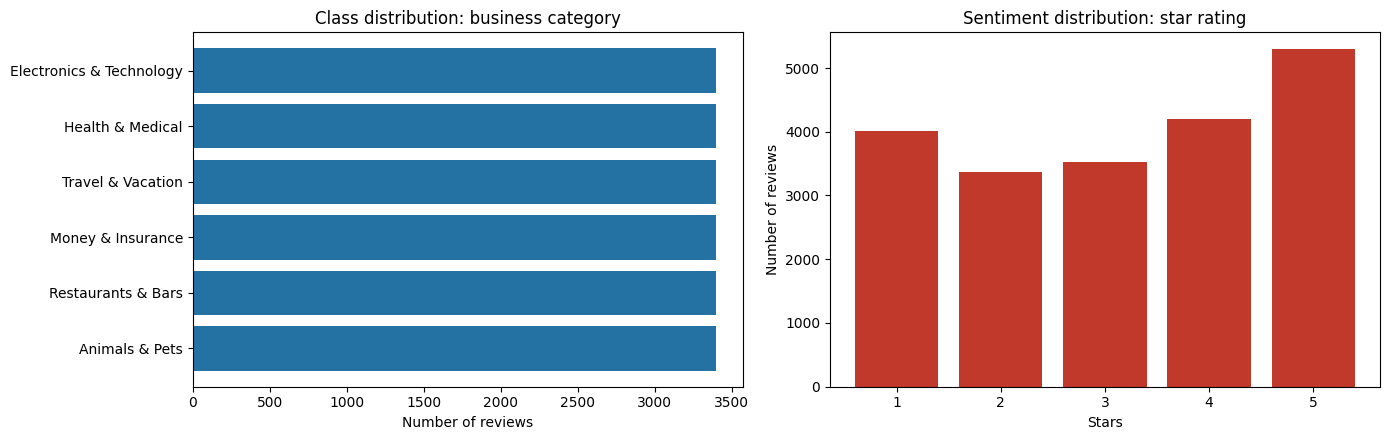

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

cat_counts = raw_df["Category"].value_counts()
axes[0].barh(cat_counts.index, cat_counts.values, color="#2471a3")
axes[0].invert_yaxis()
axes[0].set_title("Class distribution: business category")
axes[0].set_xlabel("Number of reviews")

star_counts = raw_df["Stars"].value_counts().sort_index()
axes[1].bar(star_counts.index.astype(str), star_counts.values, color="#c0392b")
axes[1].set_title("Sentiment distribution: star rating")
axes[1].set_xlabel("Stars")
axes[1].set_ylabel("Number of reviews")

plt.tight_layout()
plt.show()


Categories are balanced by construction. Stars are skewed: 5 stars is the most common rating and 2 stars the least.


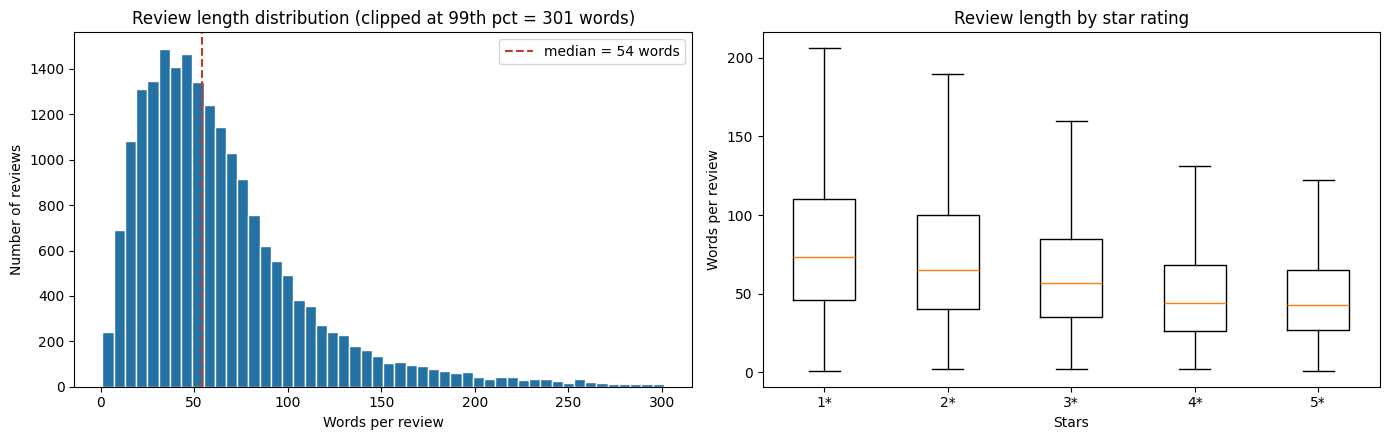

Median words per star rating:


,median_words
Stars,
1,73.0
2,65.0
3,57.0
4,44.0
5,43.0


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

cutoff = review_lengths.quantile(0.99)
axes[0].hist(review_lengths[review_lengths <= cutoff], bins=50, color="#2471a3", edgecolor="white")
axes[0].axvline(review_lengths.median(), color="#c0392b", linestyle="--",
                label=f"median = {review_lengths.median():.0f} words")
axes[0].set_title(f"Review length distribution (clipped at 99th pct = {cutoff:.0f} words)")
axes[0].set_xlabel("Words per review")
axes[0].set_ylabel("Number of reviews")
axes[0].legend()

star_values = sorted(raw_df["Stars"].unique())
by_star = [review_lengths[raw_df["Stars"] == s] for s in star_values]
axes[1].boxplot(by_star, showfliers=False)
axes[1].set_xticklabels([f"{s}*" for s in star_values])
axes[1].set_title("Review length by star rating")
axes[1].set_xlabel("Stars")
axes[1].set_ylabel("Words per review")

plt.tight_layout()
plt.show()

print("Median words per star rating:")
display(raw_df.assign(words=review_lengths).groupby("Stars")["words"].median().to_frame("median_words"))

Unhappy customers write longer reviews (see the median table above).

**Category by stars.** We cross-tabulate the two labels to check that sentiment is spread similarly across categories, so a classifier cannot shortcut through sentiment words.


Stars,1,2,3,4,5
Category,,,,,
Animals & Pets,711,509,561,690,929
Electronics & Technology,627,569,609,765,830
Health & Medical,629,561,598,700,912
Money & Insurance,668,613,590,716,813
Restaurants & Bars,665,514,508,600,1113
Travel & Vacation,712,609,655,726,698


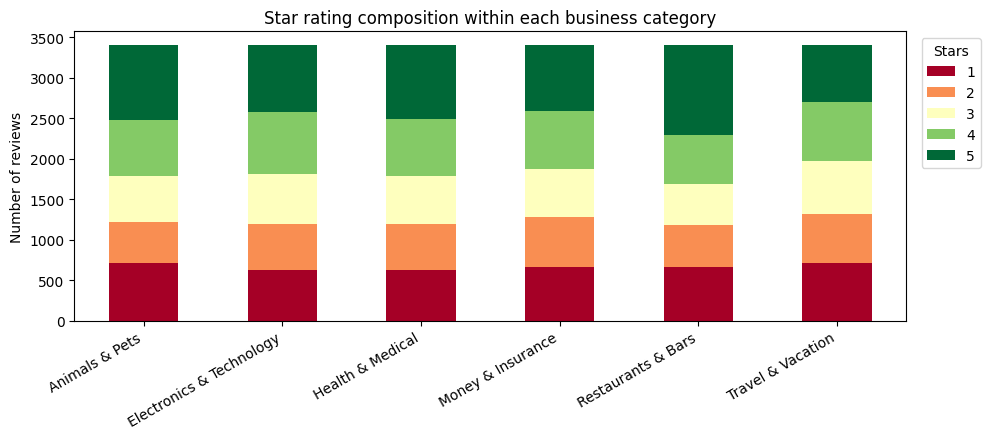

In [7]:
crosstab = pd.crosstab(raw_df["Category"], raw_df["Stars"])
display(crosstab)

ax = crosstab.plot(kind="bar", stacked=True, figsize=(10, 4.5), colormap="RdYlGn")
ax.set_title("Star rating composition within each business category")
ax.set_xlabel("")
ax.set_ylabel("Number of reviews")
ax.legend(title="Stars", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## D. Text cleaning and tokenisation

**NLTK preprocessing.** We lowercase, strip URLs and punctuation, tokenise, remove stop words and lemmatise. Negation words (`not`, `no`, `never`) are kept, since dropping them would turn "not clean" into "clean".


In [8]:
def clean_text(text: str) -> str:
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

stop_words = set(stopwords.words("english"))
negation_words = {"no", "not", "nor", "never", "none", "n't"}
stop_words = stop_words - negation_words

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

def tokenize_nltk(text: str, remove_stopwords: bool = True, lemmatize: bool = False) -> list:
    tokens = word_tokenize(clean_text(text))
    if remove_stopwords:
        tokens = [t for t in tokens if t not in stop_words]
    if lemmatize:
        tokens = [lemmatizer.lemmatize(t, pos="v") for t in tokens]
    return tokens

print(f"Stop word list: {len(stop_words)} words (negations deliberately retained)")
print()

example = raw_df["Review"].iloc[0]
display_table(pd.DataFrame({
    "Stage": ["Original", "Cleaned", "Tokens (stop words removed)", "Lemmatised"],
    "First review": [example[:170] + " ...", clean_text(example)[:170] + " ...",
                     ", ".join(tokenize_nltk(example)[:18]),
                     ", ".join(tokenize_nltk(example, lemmatize=True)[:18])],
}), "Preprocessing of one review")
display_table(pd.DataFrame([{"Word": w, "Lemma": lemmatizer.lemmatize(w, pos="v"), "Stem": stemmer.stem(w)}
                            for w in ["ordering", "charged", "waiting"]]), "Lemmatisation vs stemming")

Stop word list: 195 words (negations deliberately retained)

Preprocessing of one review


,Stage,First review
0,Original,"Poor advice given at time of purchase. Led to believe that delivery would be 24/48 hours!! BEWARE...if you live in Scotland with certain Postcodes (IV, etc)..."
1,Cleaned,poor advice given at time of purchase led to believe that delivery would be 24 48 hours beware if you live in scotland with certain postcodes iv etc deliver...
2,Tokens (stop words removed),"poor, advice, given, time, purchase, led, believe, delivery, would, 24, 48, hours, beware, live, scotland, certain, postcodes, iv"
3,Lemmatised,"poor, advice, give, time, purchase, lead, believe, delivery, would, 24, 48, hours, beware, live, scotland, certain, postcodes, iv"


Lemmatisation vs stemming


,Word,Lemma,Stem
0,ordering,order,order
1,charged,charge,charg
2,waiting,wait,wait


## E. spaCy and named entities

**spaCy and NER.** We run `en_core_web_sm` on a stratified sample of 3,000 reviews to get tokens, lemmas, part-of-speech tags and named entities.


In [9]:
SAMPLE_SIZE = 3000
working_df, _ = train_test_split(
    raw_df, train_size=SAMPLE_SIZE, random_state=RANDOM_STATE, stratify=raw_df["Category"]
)
working_df = working_df.reset_index(drop=True)
print(f"Working sample: {len(working_df):,} reviews, stratified by category")

t0 = time.time()
spacy_docs = list(NLP.pipe(working_df["Review"].tolist(), batch_size=64))
spacy_time = time.time() - t0

print()
print("spaCy tokens, lemmas and POS tags for one review (first 15 tokens):")
for t in list(spacy_docs[0])[:15]:
    print(f"  {t.text:15s} -> {t.lemma_:15s} ({t.pos_})")

Working sample: 3,000 reviews, stratified by category

spaCy tokens, lemmas and POS tags for one review (first 15 tokens):
  Used            -> use             (VERB)
  this            -> this            (DET)
  company         -> company         (NOUN)
  twice           -> twice           (ADV)
  with            -> with            (ADP)
  no              -> no              (DET)
  issue           -> issue           (NOUN)
  ,               -> ,               (PUNCT)
  however         -> however         (ADV)
  my              -> my              (PRON)
  third           -> third           (ADJ)
  order           -> order           (NOUN)
  (               -> (               (PUNCT)
  27.11.24        -> 27.11.24        (NOUN)
  )               -> )               (PUNCT)


In [10]:
entity_rows = [
    {"review_id": rid, "category": cat, "entity_text": ent.text, "entity_label": ent.label_}
    for rid, cat, doc in zip(working_df["review_id"], working_df["Category"], spacy_docs)
    for ent in doc.ents
]
entities_df = pd.DataFrame(entity_rows)

print(f"Entities found: {len(entities_df):,} across {entities_df['entity_label'].nunique()} types "
      f"({len(entities_df) / len(working_df):.1f} per review)")
print()
display(entities_df.head(10))

top_entities = []
for label in ["ORG", "GPE", "MONEY", "DATE"]:
    top = entities_df[entities_df["entity_label"] == label]["entity_text"].value_counts().head(5)
    top_entities.append({"Entity type": label,
                         "Most frequent (count)": ", ".join(f"{t} ({n})" for t, n in top.items())})
display_table(pd.DataFrame(top_entities), "Most frequent entities of the types the brief names")

Entities found: 8,018 across 18 types (2.7 per review)



,review_id,category,entity_text,entity_label
0,12555,Health & Medical,third,ORDINAL
1,12555,Health & Medical,27.11.24,CARDINAL
2,12555,Health & Medical,149.00,MONEY
3,9489,Electronics & Technology,VAX,PRODUCT
4,9489,Electronics & Technology,Mollie,PERSON
5,14198,Restaurants & Bars,second,ORDINAL
6,14198,Restaurants & Bars,first,ORDINAL
7,14198,Restaurants & Bars,3 months,DATE
8,14198,Restaurants & Bars,second,ORDINAL
9,14198,Restaurants & Bars,a week,DATE


Most frequent entities of the types the brief names


,Entity type,Most frequent (count)
0,ORG,"Royal Mail (17), DPD (13), NHS (11), Amazon (11), First Direct (9)"
1,GPE,"UK (34), London (16), England (9), China (9), Singapore (8)"
2,MONEY,"100 (11), 50 (10), 25 (9), 5 (9), 30 (9)"
3,DATE,"today (63), next day (59), the day (55), Christmas (53), the next day (45)"


## F. Token and entity visualisations

We chart the most frequent lemmatised tokens, the entity types and a word cloud, then the most distinctive terms per category.


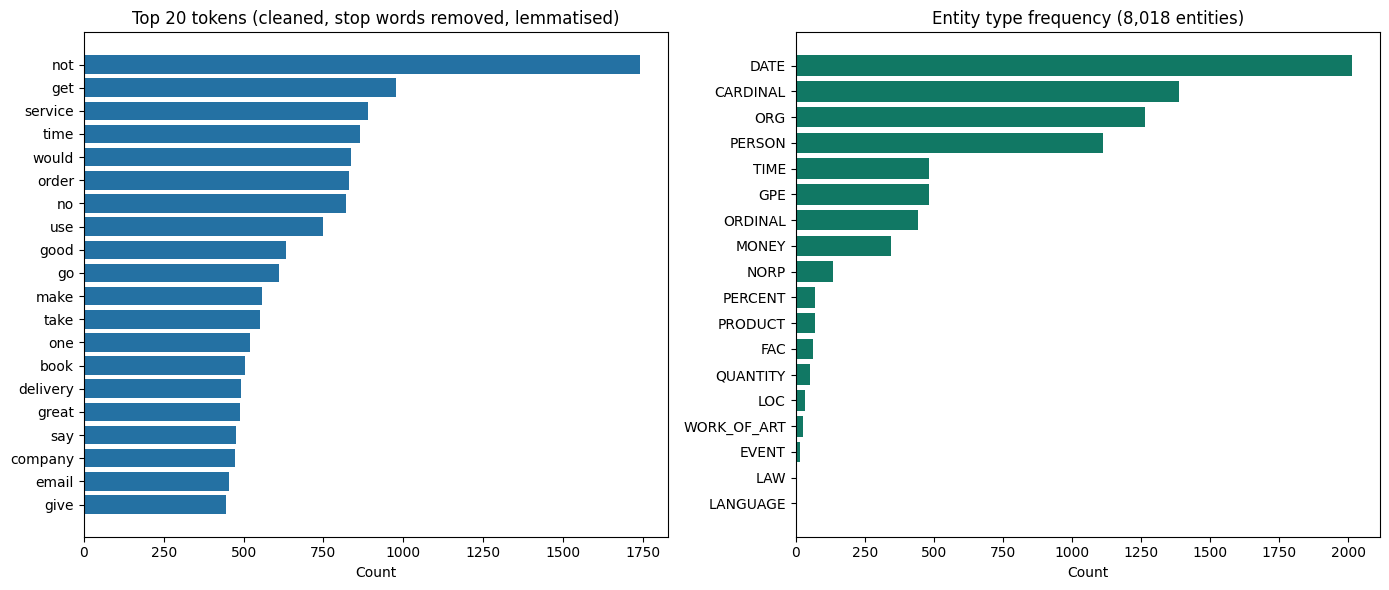

In [11]:
nltk_tokens_lemmatised = [tok for text in working_df["Review"]
                          for tok in tokenize_nltk(text, lemmatize=True)]
token_freq = Counter(nltk_tokens_lemmatised)
top_tokens = pd.DataFrame(token_freq.most_common(20), columns=["token", "count"])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh(top_tokens["token"], top_tokens["count"], color="#2471a3")
axes[0].invert_yaxis()
axes[0].set_title("Top 20 tokens (cleaned, stop words removed, lemmatised)")
axes[0].set_xlabel("Count")

entity_counts = entities_df["entity_label"].value_counts()
axes[1].barh(entity_counts.index, entity_counts.values, color="#117864")
axes[1].invert_yaxis()
axes[1].set_title(f"Entity type frequency ({len(entities_df):,} entities)")
axes[1].set_xlabel("Count")

plt.tight_layout()
plt.show()

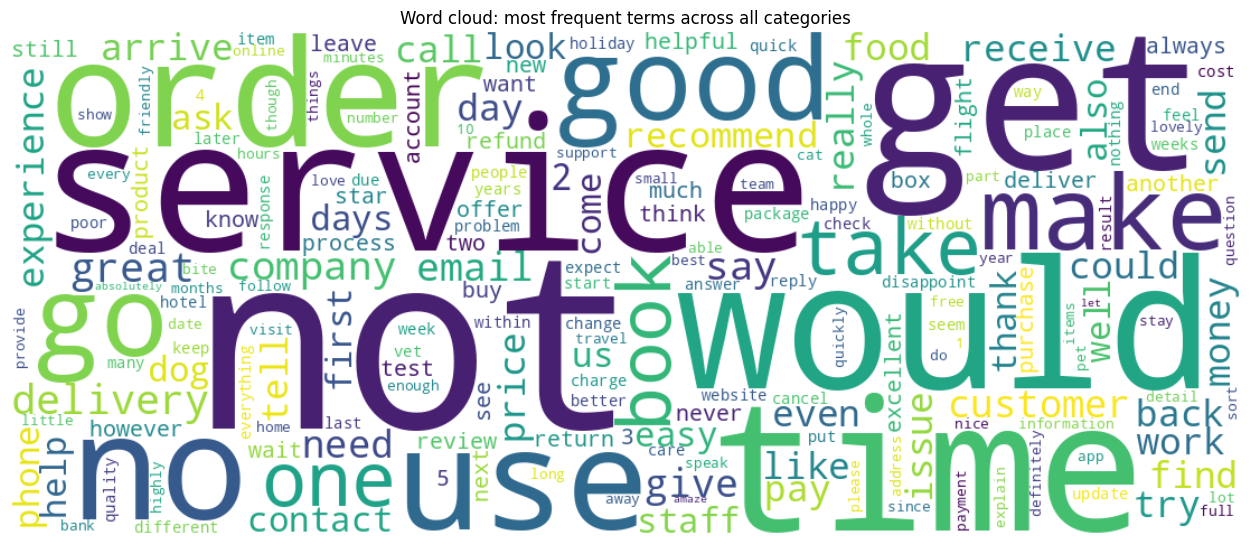

In [12]:
wc = WordCloud(width=1100, height=450, background_color="white",
               colormap="viridis", random_state=RANDOM_STATE)
wc = wc.generate_from_frequencies(token_freq)

plt.figure(figsize=(13, 5.5))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Word cloud: most frequent terms across all categories")
plt.tight_layout()
plt.show()

**Distinctive terms per category.** Overall counts are dominated by words every sector uses ("service", "order", "time"). We therefore use TF-IDF over one pooled document per category to list each category's most distinctive terms, first on all reviews and then on 1-2 star reviews only.


In [13]:
category_docs = (raw_df.assign(clean=raw_df["Review"].apply(clean_text))
                       .groupby("Category")["clean"].apply(" ".join))

vec = TfidfVectorizer(stop_words="english", max_features=6000)
matrix = vec.fit_transform(category_docs)
vocab = np.array(vec.get_feature_names_out())

theme_table = {}
for i, cat in enumerate(category_docs.index):
    row = matrix[i].toarray().ravel()
    theme_table[cat] = vocab[row.argsort()[::-1][:10]]

print("Most distinctive terms per category (all reviews):")
display(pd.DataFrame(theme_table))

Most distinctive terms per category (all reviews):


,Animals & Pets,Electronics & Technology,Health & Medical,Money & Insurance,Restaurants & Bars,Travel & Vacation
0,dog,delivery,service,money,food,booking
1,vet,service,time,account,service,flight
2,delivery,good,test,service,order,hotel
3,service,time,good,time,good,booked
4,order,customer,just,good,delivery,holiday
5,time,phone,day,just,time,time
6,vets,day,delivery,company,great,good
7,good,order,order,bank,staff,service
8,food,company,dentist,customer,just,book
9,just,new,great,easy,really,great


In [14]:
complaints = raw_df[raw_df["Stars"] <= 2]
complaint_docs = (complaints.assign(clean=complaints["Review"].apply(clean_text))
                            .groupby("Category")["clean"].apply(" ".join))

vec_c = TfidfVectorizer(stop_words="english", max_features=6000)
matrix_c = vec_c.fit_transform(complaint_docs)
vocab_c = np.array(vec_c.get_feature_names_out())

complaint_themes = {cat: vocab_c[matrix_c[i].toarray().ravel().argsort()[::-1][:10]]
                    for i, cat in enumerate(complaint_docs.index)}

print(f"Distinctive terms in 1-2 star reviews only ({len(complaints):,} reviews):")
display(pd.DataFrame(complaint_themes))

Distinctive terms in 1-2 star reviews only (7,387 reviews):


,Animals & Pets,Electronics & Technology,Health & Medical,Money & Insurance,Restaurants & Bars,Travel & Vacation
0,vet,delivery,service,money,food,hotel
1,dog,service,time,account,order,flight
2,vets,customer,test,service,service,booking
3,order,order,told,time,ordered,booked
4,time,time,just,company,time,time
5,pet,phone,money,just,staff,holiday
6,service,day,order,don,delivery,service
7,just,days,clinic,bank,just,company
8,cat,company,company,customer,customer,refund
9,delivery,ordered,day,loan,like,told


**Complaint topics with NMF.** We factorise the TF-IDF matrix of the negative (1-2 star) reviews into 10 topics. The table gives each topic's share of complaints, top words and most common sector.


In [15]:
N_THEMES = 10

neg_clean = complaints["Review"].apply(clean_text)
CONTRACTION_FRAGMENTS = {"didn", "don", "doesn", "wasn", "isn", "couldn", "wouldn",
                         "haven", "hasn", "aren", "weren", "ve", "ll", "just"}
vec_nmf = TfidfVectorizer(stop_words=list(ENGLISH_STOP_WORDS | CONTRACTION_FRAGMENTS),
                          min_df=5, max_df=0.5)
X_neg = vec_nmf.fit_transform(neg_clean)
nmf_terms = np.array(vec_nmf.get_feature_names_out())

nmf = NMF(n_components=N_THEMES, init="nndsvd", random_state=RANDOM_STATE, max_iter=400)
doc_theme = nmf.fit_transform(X_neg)

assigned = doc_theme.argmax(axis=1)
share = np.bincount(assigned, minlength=N_THEMES) / len(neg_clean)

sector_mix = []
for k in range(N_THEMES):
    top = complaints["Category"].values[assigned == k]
    name, frac = pd.Series(top).value_counts(normalize=True).iloc[[0]].reset_index().values[0]
    sector_mix.append(f"{name} ({frac:.0%})")
nmf_themes = pd.DataFrame({
    "Theme": range(1, N_THEMES + 1),
    "Share of complaints": [f"{s:.1%}" for s in share],
    "Top terms": [", ".join(nmf_terms[row.argsort()[::-1][:8]]) for row in nmf.components_],
    "Most common sector": sector_mix,
})
print(f"NMF on {len(neg_clean):,} negative reviews, {N_THEMES} themes, vocabulary {len(nmf_terms):,}")
display(nmf_themes.style.hide(axis="index"))

NMF on 7,387 negative reviews, 10 themes, vocabulary 5,304


Theme,Share of complaints,Top terms,Most common sector
1,20.4%,"time, told, like, dog, really, vet, good, experience",Animals & Pets (26%)
2,7.2%,"order, placed, stock, ordered, items, received, arrive, cancelled",Restaurants & Bars (31%)
3,9.6%,"food, staff, arrived, ordered, eat, dog, meal, drinks",Restaurants & Bars (68%)
4,7.2%,"delivery, day, days, delivered, paid, waiting, parcel, time",Electronics & Technology (37%)
5,11.6%,"booking, hotel, flight, booked, book, holiday, travel, flights",Travel & Vacation (89%)
6,12.9%,"service, customer, poor, terrible, good, support, team, shocking",Money & Insurance (24%)
7,6.9%,"item, refund, product, ordered, stock, arrived, return, items",Electronics & Technology (38%)
8,10.2%,"money, account, bank, refund, card, transfer, waste, credit",Money & Insurance (66%)
9,10.7%,"email, received, sent, phone, response, reply, emails, contact",Money & Insurance (24%)
10,3.3%,"test, results, tests, day, kit, pcr, blood, result",Health & Medical (87%)


## G. NLTK vs spaCy

We compare the two tools on the same 3,000 reviews, excluding punctuation.


In [16]:
def nltk_corpus_tokens(texts, **kwargs) -> list:
    return [tok for text in texts for tok in tokenize_nltk(text, **kwargs)]

def spacy_corpus_tokens(docs, drop_stopwords: bool = False) -> list:
    return [t.text.lower() for doc in docs for t in doc
            if not t.is_space and not t.is_punct and not (drop_stopwords and t.is_stop)]

t0 = time.time()
nltk_lemmas = nltk_corpus_tokens(working_df["Review"], lemmatize=True)
nltk_time = time.time() - t0

nltk_all = nltk_corpus_tokens(working_df["Review"], remove_stopwords=False)
nltk_nostop = nltk_corpus_tokens(working_df["Review"])
spacy_all = spacy_corpus_tokens(spacy_docs)
spacy_nostop = spacy_corpus_tokens(spacy_docs, drop_stopwords=True)

comparison_df = pd.DataFrame({
    "Metric": [
        "Total tokens",
        "Vocabulary size",
        "Tokens after stop word removal",
        "Stop words removed (%)",
        "Lemmatisation example",
        "Entities found",
        "Processing time, 3,000 reviews",
        "Reviews per second",
    ],
    "NLTK": [
        f"{len(nltk_all):,}",
        f"{len(set(nltk_all)):,}",
        f"{len(nltk_nostop):,}",
        f"{100 * (1 - len(nltk_nostop) / len(nltk_all)):.1f}% (custom list, negations kept)",
        f"'ordering' -> '{lemmatizer.lemmatize('ordering', pos='v')}' (POS supplied manually)",
        "None (no entity step in this pipeline)",
        f"{nltk_time:.1f}s (tokens, stop words, lemmas)",
        f"{len(working_df) / nltk_time:,.0f}",
    ],
    "spaCy": [
        f"{len(spacy_all):,}",
        f"{len(set(spacy_all)):,}",
        f"{len(spacy_nostop):,}",
        f"{100 * (1 - len(spacy_nostop) / len(spacy_all)):.1f}% (built-in is_stop flag)",
        f"'ordering' -> '{NLP('ordering')[0].lemma_}' (POS inferred automatically)",
        f"{len(entities_df):,} entities, {entities_df['entity_label'].nunique()} types",
        f"{spacy_time:.1f}s (tokens, lemmas, POS, entities)",
        f"{len(working_df) / spacy_time:,.0f}",
    ],
})
display(comparison_df)

,Metric,NLTK,spaCy
0,Total tokens,"203,695","203,679"
1,Vocabulary size,"11,708","12,369"
2,Tokens after stop word removal,"104,781","89,364"
3,Stop words removed (%),"48.6% (custom list, negations kept)",56.1% (built-in is_stop flag)
4,Lemmatisation example,'ordering' -> 'order' (POS supplied manually),'ordering' -> 'order' (POS inferred automatically)
5,Entities found,None (no entity step in this pipeline),"8,018 entities, 18 types"
6,"Processing time, 3,000 reviews","2.3s (tokens, stop words, lemmas)","56.1s (tokens, lemmas, POS, entities)"
7,Reviews per second,"1,281",53


Token counts are almost identical, but spaCy has the larger vocabulary and removes more stop words, and only spaCy gives entities.

**Practical implications.** The processing-time row shows the cost of spaCy's fuller pipeline, so we use NLTK for bulk tokenising and spaCy for the entity pass.


**Keeping versus removing stop words.** We compare token counts, vocabulary and the most frequent tokens with stop words kept and removed.


In [17]:
experiment = pd.DataFrame({
    "Setting": ["Stop words kept", "Stop words removed (negations kept)"],
    "Total tokens": [f"{len(nltk_all):,}", f"{len(nltk_nostop):,}"],
    "Vocabulary size": [f"{len(set(nltk_all)):,}", f"{len(set(nltk_nostop)):,}"],
    "Token reduction": ["-", f"{100 * (1 - len(nltk_nostop) / len(nltk_all)):.1f}%"],
})
display(experiment)

display_table(pd.DataFrame({
    "Setting": ["Stop words kept", "Stop words removed"],
    "Top 10 tokens": [", ".join(w for w, _ in Counter(nltk_all).most_common(10)),
                      ", ".join(w for w, _ in Counter(nltk_nostop).most_common(10))],
}), "Most frequent tokens")

surviving = [w for w in ["not", "no", "never", "nor"] if w in set(nltk_nostop)]
print(f"Negation words surviving removal: {surviving}")

,Setting,Total tokens,Vocabulary size,Token reduction
0,Stop words kept,"203,695","11,708",-
1,Stop words removed (negations kept),"104,781","11,564",48.6%


Most frequent tokens


,Setting,Top 10 tokens
0,Stop words kept,"the, to, and, i, a, was, it, for, of, my"
1,Stop words removed,"not, would, no, service, time, good, one, get, delivery, great"


Negation words surviving removal: ['not', 'no', 'never', 'nor']


Removal cuts about half of the tokens but barely changes the vocabulary. Without removal the most frequent tokens are function words (`the`, `to`, `and`); after it they are content words and negations. `not`, `no`, `never` and `nor` survive.


## Reflection

**What this means downstream.** Stop word removal is a choice of list, not a standard step: spaCy's list removes more tokens than ours. Negative reviews are longer, so any truncation limit removes more negative text. We therefore prepare the text differently for the category model, the sentiment model and Word2Vec.


---

# Task 2 — Classical NLP Baseline for Complaint Category Classification


## A. Task framing and split

**Target and split.** We predict `Category` and add sentiment as a second target later. An 80/20 stratified split (16,320 train, 4,080 test) is reused unchanged in Tasks 3 and 4. The Linear SVM for category sees text without stop words; the one for sentiment keeps them.


In [18]:
def preprocess_category(text: str) -> str:
    return " ".join(tokenize_nltk(text, remove_stopwords=True, lemmatize=True))

def preprocess_sentiment(text: str) -> str:
    return " ".join(tokenize_nltk(text, remove_stopwords=False, lemmatize=True))

def make_vectorizer() -> FeatureUnion:
    return FeatureUnion([
        ("word", TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 4), min_df=2)),
    ])

X_cat = raw_df["Review"].apply(preprocess_category)
X_sent = raw_df["Review"].apply(preprocess_sentiment)
y = raw_df["Category"]

X_train, X_test, y_train, y_test = train_test_split(
    X_cat, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"Train: {len(X_train):,}   Test: {len(X_test):,}")
print()
print("The same review, prepared two ways:")
print("  raw       :", raw_df["Review"].iloc[0][:110])
print("  category  :", X_cat.iloc[0][:110])
print("  sentiment :", X_sent.iloc[0][:110])
print()
display(y_train.value_counts().to_frame("train_count"))

Train: 16,320   Test: 4,080

The same review, prepared two ways:
  raw       : Poor advice given at time of purchase. Led to believe that delivery would be 24/48 hours!! BEWARE...if you liv
  category  : poor advice give time purchase lead believe delivery would 24 48 hours beware live scotland certain postcodes 
  sentiment : poor advice give at time of purchase lead to believe that delivery would be 24 48 hours beware if you live in 



,train_count
Category,
Travel & Vacation,2720
Money & Insurance,2720
Animals & Pets,2720
Restaurants & Bars,2720
Health & Medical,2720
Electronics & Technology,2720


## B. Features and model

**Features and model selection.** We use TF-IDF over word and character n-grams, since characters cope with misspellings. We compare Logistic Regression and Linear SVM by 5-fold cross-validation on the training data only, then refit the winner, Linear SVM, on the full training set.


In [19]:
candidates = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Linear SVM": LinearSVC(random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows, model_scores = [], {}
for name, model in candidates.items():
    pipe = Pipeline([("features", make_vectorizer()), ("clf", model)])
    t0 = time.time()
    scores = cross_val_score(pipe, X_train, y_train, cv=cv,
                             scoring="f1_macro", n_jobs=-1)
    rows.append({"Model": name,
                 "CV macro F1": f"{scores.mean():.4f}",
                 "CV std": f"{scores.std():.4f}",
                 "CV time (s)": f"{time.time() - t0:.1f}"})
    model_scores[name] = scores.mean()

display_table(pd.DataFrame(rows), "5-fold cross-validation on training data only")

best_name = max(model_scores, key=model_scores.get)
print(f"Selected: {best_name} (CV macro F1 {model_scores[best_name]:.4f})")
print()

classifier = Pipeline([("features", make_vectorizer()),
                       ("clf", candidates[best_name])])
start = time.time()
classifier.fit(X_train, y_train)
classical_train_time = time.time() - start

feature_union = classifier.named_steps["features"]
word_vocab = len(feature_union.transformer_list[0][1].vocabulary_)
char_vocab = len(feature_union.transformer_list[1][1].vocabulary_)
display_table(pd.DataFrame({
    "Feature block": ["Word (unigrams + bigrams, min_df=2)", "Character (char_wb 3-4 grams, min_df=2)", "Total"],
    "Features": [f"{word_vocab:,}", f"{char_vocab:,}", f"{word_vocab + char_vocab:,}"],
}), "TF-IDF feature space")
print(f"Training time: {classical_train_time:.1f}s")

5-fold cross-validation on training data only


,Model,CV macro F1,CV std,CV time (s)
0,Logistic Regression,0.8052,0.0043,81.8
1,Linear SVM,0.8164,0.0055,31.2


Selected: Linear SVM (CV macro F1 0.8164)

TF-IDF feature space


,Feature block,Features
0,"Word (unigrams + bigrams, min_df=2)","74,227"
1,"Character (char_wb 3-4 grams, min_df=2)","26,437"
2,Total,"100,664"


Training time: 8.1s


We score the model on the test set with accuracy, macro-averaged precision, recall and F1, and a confusion matrix.


In [20]:
start = time.time()
y_pred = classifier.predict(X_test)
classical_infer_time = time.time() - start

classical_accuracy = accuracy_score(y_test, y_pred)
classical_macro_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
classical_weighted_f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

report_tables(y_test, y_pred, sorted(y.unique()), "Linear SVM (category)")

Linear SVM (category): test-set metrics


,Accuracy,Macro precision,Macro recall,Macro F1,Weighted F1,Test reviews
0,0.8260,0.8278,0.8260,0.8258,0.8258,"4,080"


Linear SVM (category): per-class results


,Class,precision,recall,f1-score,support
0,Animals & Pets,0.8465,0.7706,0.8068,680
1,Electronics & Technology,0.7524,0.7956,0.7734,680
2,Health & Medical,0.8199,0.7765,0.7976,680
3,Money & Insurance,0.8062,0.9118,0.8558,680
4,Restaurants & Bars,0.8383,0.8235,0.8309,680
5,Travel & Vacation,0.9032,0.8779,0.8904,680


Accuracy and macro F1 are almost identical because the classes are balanced.


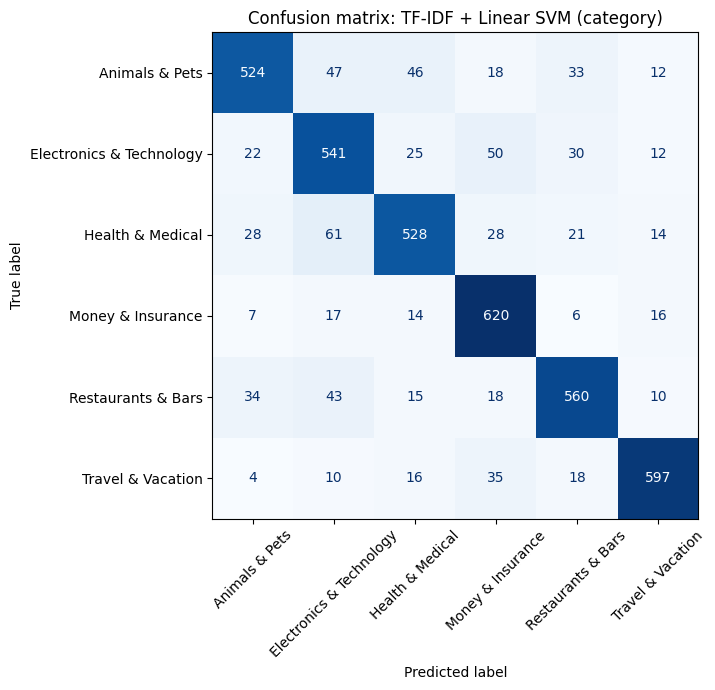

Most confused category pairs


,True category,Predicted category,Count
0,Health & Medical,Electronics & Technology,61
1,Electronics & Technology,Money & Insurance,50
2,Animals & Pets,Electronics & Technology,47
3,Animals & Pets,Health & Medical,46
4,Restaurants & Bars,Electronics & Technology,43
5,Travel & Vacation,Money & Insurance,35


In [21]:
labels_sorted = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels_sorted)

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels_sorted).plot(
    ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
plt.title("Confusion matrix: TF-IDF + Linear SVM (category)")
plt.tight_layout()
plt.show()

off = cm.copy()
np.fill_diagonal(off, 0)
pairs = [(labels_sorted[i], labels_sorted[j], off[i, j])
         for i in range(len(labels_sorted)) for j in range(len(labels_sorted)) if off[i, j] > 0]
pairs.sort(key=lambda t: -t[2])
display_table(pd.DataFrame(pairs[:6], columns=["True category", "Predicted category", "Count"]),
              "Most confused category pairs")

The most confused pairs mostly involve `Electronics & Technology`.


## D. Cost of the model

We record training and prediction time for the selected model, so Task 4 can compare the transformer on cost as well as accuracy.


In [22]:
best_baseline = {
    "accuracy": classical_accuracy,
    "macro_f1": classical_macro_f1,
    "train_time": classical_train_time,
    "infer_time": classical_infer_time,
    "pipeline": classifier,
}

display_table(pd.DataFrame([{
    "Selected model": best_name,
    "Test accuracy": f"{best_baseline['accuracy']:.4f}",
    "Test macro F1": f"{best_baseline['macro_f1']:.4f}",
    "Train (s)": f"{best_baseline['train_time']:.1f}",
    "Predict (s)": f"{best_baseline['infer_time']:.2f}",
    "Reviews/sec": f"{len(X_test) / best_baseline['infer_time']:,.0f}",
}]), "Classical baseline, as carried into Task 4")

print(f"Task 4 compares the fine-tuned transformer against this {best_name}.")

Classical baseline, as carried into Task 4


,Selected model,Test accuracy,Test macro F1,Train (s),Predict (s),Reviews/sec
0,Linear SVM,0.8260,0.8258,8.1,0.94,"4,352"


Task 4 compares the fine-tuned transformer against this Linear SVM.


## E. Misclassified examples

We show six randomly chosen misclassified test reviews, with their original text.


In [23]:
results_df = pd.DataFrame({
    "review": raw_df.loc[X_test.index, "Review"],
    "actual": y_test,
    "predicted": y_pred,
    "stars": raw_df.loc[X_test.index, "Stars"],
}, index=X_test.index)

misclassified_df = results_df[results_df["actual"] != results_df["predicted"]]
print(f"Misclassified: {len(misclassified_df):,} / {len(results_df):,} "
      f"({100 * len(misclassified_df) / len(results_df):.1f}%)")
print()
display(misclassified_df.sample(6, random_state=RANDOM_STATE))

Misclassified: 710 / 4,080 (17.4%)



,review,actual,predicted,stars
17576,"The ordering seemed straightforward and I chose a delivery date. The items are as expected. The 3 stars are for the delivery - spread over 4 days, with the ...",Restaurants & Bars,Electronics & Technology,3
3483,I paid for next day delivery however I never received an email confirmation and it did not arrive the next day. After waiting a few days of not hearing anyt...,Animals & Pets,Health & Medical,3
10732,"Your service is fantastic and awesome. Ones you follow the required process,you will get the solution to the support you need with the shortest time,I would...",Money & Insurance,Restaurants & Bars,5
8563,If there's anything ive learned from this place it's to record your calls when your talking to the advisors due to lack of communication they'll tell you so...,Health & Medical,Money & Insurance,1
12572,Quick and straight forward! I was given all the information I needed to get my system up and running smoothly!,Electronics & Technology,Money & Insurance,5
10763,Does what it says on the tin Unfussy and efficient Recommended,Travel & Vacation,Animals & Pets,4


### Interpretation

**Why they fail.** Some reviews are short generic thanks with no topic words, so there is nothing to classify. Others are labelled by the business's sector but describe a payment dispute, so the model is arguably right about the subject and wrong about the sector. This is why `Money & Insurance` has the highest recall but lower precision (see the per-category table): it absorbs billing complaints from other sectors.


## F. Optional experiment: NER features

**NER features.** We count eight entity types per review over the full corpus and append them to the TF-IDF features, with the same model, to see whether classification improves. Task 1 ran the full spaCy pipeline on a 3,000-review sample; here only the entity recogniser runs, on all 20,400 reviews, because every review needs features.


In [24]:
NER_ONLY = spacy.load("en_core_web_sm", disable=["tagger", "parser", "attribute_ruler", "lemmatizer"])

ENTITY_TYPES = ["ORG", "PERSON", "GPE", "MONEY", "DATE", "PRODUCT", "CARDINAL", "TIME"]

t0 = time.time()
ner_counts = []
for doc in NER_ONLY.pipe(raw_df["Review"].tolist(), batch_size=256):
    counts = Counter(ent.label_ for ent in doc.ents)
    ner_counts.append([counts.get(lbl, 0) for lbl in ENTITY_TYPES])
ner_features = pd.DataFrame(ner_counts, columns=ENTITY_TYPES, index=raw_df.index)
print(f"NER features built for {len(ner_features):,} reviews in {time.time() - t0:.0f}s")
print()
print("Mean entity counts per review, by category:")
display(ner_features.join(raw_df["Category"]).groupby("Category").mean().round(2))

NER features built for 20,400 reviews in 98s

Mean entity counts per review, by category:


,ORG,PERSON,GPE,MONEY,DATE,PRODUCT,CARDINAL,TIME
Category,,,,,,,,
Animals & Pets,0.35,0.38,0.15,0.12,0.70,0.03,0.43,0.14
Electronics & Technology,0.46,0.33,0.11,0.12,0.79,0.03,0.42,0.15
Health & Medical,0.37,0.32,0.17,0.12,0.75,0.02,0.44,0.19
Money & Insurance,0.46,0.34,0.14,0.13,0.61,0.03,0.32,0.10
Restaurants & Bars,0.40,0.41,0.17,0.10,0.55,0.02,0.56,0.18
Travel & Vacation,0.60,0.49,0.33,0.17,0.63,0.02,0.49,0.27


In [25]:
tfidf = make_vectorizer()
Xtr_tfidf = tfidf.fit_transform(X_train)
Xte_tfidf = tfidf.transform(X_test)

scaler = StandardScaler()
Xtr_ner = scaler.fit_transform(ner_features.loc[X_train.index])
Xte_ner = scaler.transform(ner_features.loc[X_test.index])

Xtr_combined = hstack([Xtr_tfidf, csr_matrix(Xtr_ner)]).tocsr()
Xte_combined = hstack([Xte_tfidf, csr_matrix(Xte_ner)]).tocsr()

combo = clone(classifier.named_steps["clf"]).fit(Xtr_combined, y_train)
pred_combo = combo.predict(Xte_combined)

acc_combo = accuracy_score(y_test, pred_combo)
f1_combo = f1_score(y_test, pred_combo, average="macro", zero_division=0)

display(pd.DataFrame({
    "Feature set": ["TF-IDF only", f"TF-IDF + {len(ENTITY_TYPES)} NER count features"],
    "Accuracy": [f"{classical_accuracy:.4f}", f"{acc_combo:.4f}"],
    "Macro F1": [f"{classical_macro_f1:.4f}", f"{f1_combo:.4f}"],
}))
print(f"Change: accuracy {acc_combo - classical_accuracy:+.4f}, macro F1 {f1_combo - classical_macro_f1:+.4f}")

,Feature set,Accuracy,Macro F1
0,TF-IDF only,0.8260,0.8258
1,TF-IDF + 8 NER count features,0.8252,0.8251


Change: accuracy -0.0007, macro F1 -0.0007


### Did the NER features help?

No: accuracy and macro F1 barely change, which is noise. Entity counts differ only modestly across categories, and what matters is the entity's identity (for example Royal Mail), which TF-IDF already captures.


## G. Sentiment classification

**Sentiment target.** We collapse stars into negative (1-2), neutral (3) and positive (4-5) and train the same model type on text that keeps stop words. We also score a binary version without the neutral class to show what neutral costs.


Sentiment class distribution:


,count
Stars,
positive,9492
negative,7387
neutral,3521


Linear SVM (sentiment): test-set metrics


,Accuracy,Macro precision,Macro recall,Macro F1,Weighted F1,Test reviews
0,0.7441,0.6466,0.6415,0.6359,0.7263,"4,080"


Linear SVM (sentiment): per-class results


,Class,precision,recall,f1-score,support
0,negative,0.7135,0.8261,0.7657,1420
1,neutral,0.3819,0.2260,0.2839,708
2,positive,0.8443,0.8724,0.8582,1952


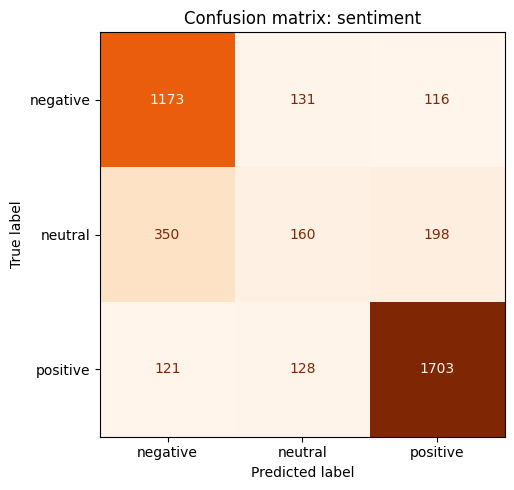

What the neutral class costs


,Framing,Test reviews,Macro F1
0,3-class (negative / neutral / positive),"4,080",0.6359
1,"Binary (negative / positive, 3-star reviews dropped)","3,372",0.9089


Retaining the neutral class costs 0.2730 macro F1.


In [26]:
def stars_to_sentiment(stars: int) -> str:
    if stars <= 2:
        return "negative"
    if stars == 3:
        return "neutral"
    return "positive"

y_sent = raw_df["Stars"].apply(stars_to_sentiment)
print("Sentiment class distribution:")
display(y_sent.value_counts().to_frame("count"))

Xs_train, Xs_test = X_sent.loc[X_train.index], X_sent.loc[X_test.index]
ys_train, ys_test = y_sent.loc[X_train.index], y_sent.loc[X_test.index]

sentiment_clf = Pipeline([
    ("features", make_vectorizer()),
    ("clf", clone(classifier.named_steps["clf"])),
]).fit(Xs_train, ys_train)

ys_pred = sentiment_clf.predict(Xs_test)
sentiment_accuracy = accuracy_score(ys_test, ys_pred)
sentiment_macro_f1 = f1_score(ys_test, ys_pred, average="macro", zero_division=0)

report_tables(ys_test, ys_pred, ["negative", "neutral", "positive"], "Linear SVM (sentiment)")

fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(ys_test, ys_pred, labels=["negative", "neutral", "positive"]),
    display_labels=["negative", "neutral", "positive"]).plot(ax=ax, cmap="Oranges", colorbar=False)
plt.title("Confusion matrix: sentiment")
plt.tight_layout()
plt.show()

binary_mask = raw_df.loc[X_train.index, "Stars"] != 3
binary_mask_test = raw_df.loc[X_test.index, "Stars"] != 3
binary_clf = Pipeline([
    ("features", make_vectorizer()),
    ("clf", clone(classifier.named_steps["clf"])),
]).fit(Xs_train[binary_mask], ys_train[binary_mask])
binary_pred = binary_clf.predict(Xs_test[binary_mask_test])
binary_macro_f1 = f1_score(ys_test[binary_mask_test], binary_pred,
                           average="macro", zero_division=0)

display_table(pd.DataFrame([
    {"Framing": "3-class (negative / neutral / positive)",
     "Test reviews": f"{len(ys_test):,}",
     "Macro F1": f"{sentiment_macro_f1:.4f}"},
    {"Framing": "Binary (negative / positive, 3-star reviews dropped)",
     "Test reviews": f"{int(binary_mask_test.sum()):,}",
     "Macro F1": f"{binary_macro_f1:.4f}"},
]), "What the neutral class costs")
print(f"Retaining the neutral class costs "
      f"{binary_macro_f1 - sentiment_macro_f1:.4f} macro F1.")

## Discussion

**What the classical model can do.** It routes reviews well, far above chance, trains quickly, and its predictions trace back to n-grams. **Its limits.** It fails on reviews without topic words, confuses a complaint's subject with the business sector, and cannot resolve hedging, so neutral stays weak.


---

# Task 3 — Semantic Embeddings for Feedback Retrieval and Similarity Analysis


## A. Training Word2Vec

**Word2Vec.** We train a skip-gram model (100 dimensions, window 5, `min_count=5`, 10 epochs) on Task 2's training reviews. Stop words are kept and nothing is lemmatised, so variants such as _cancelled_ and _canceled_ stay neighbours. A single worker keeps training reproducible.


In [27]:
tokenized_reviews = [tokenize_nltk(text, remove_stopwords=False) for text in raw_df["Review"]]
total_tokens = sum(len(t) for t in tokenized_reviews)

assert (raw_df.index == np.arange(len(raw_df))).all(), "positional indexing assumed below"
index_idx = X_train.index.to_numpy()
query_idx = np.random.default_rng(RANDOM_STATE).choice(
    X_test.index.to_numpy(), size=1000, replace=False)

t0 = time.time()
word2vec_model = Word2Vec(
    sentences=[tokenized_reviews[i] for i in index_idx],
    vector_size=100,
    window=5,
    min_count=5,
    sg=1,
    seed=RANDOM_STATE,
    workers=1,
    epochs=10,
)
display_table(pd.DataFrame({
    "Item": ["Training time", "Indexed reviews", "Queries", "Tokens in the full corpus", "Vocabulary (min_count=5)", "Dimensions"],
    "Value": [f"{time.time() - t0:.0f}s", f"{len(index_idx):,} (Task 2's training rows)",
              f"{len(query_idx):,} (drawn from Task 2's test set)", f"{total_tokens:,}",
              f"{len(word2vec_model.wv):,} words", str(word2vec_model.vector_size)],
}), "Word2Vec training")

Word2Vec training


,Item,Value
0,Training time,53s
1,Indexed reviews,"16,320 (Task 2's training rows)"
2,Queries,"1,000 (drawn from Task 2's test set)"
3,Tokens in the full corpus,"1,412,191"
4,Vocabulary (min_count=5),"8,225 words"
5,Dimensions,100


## B. Word similarity

**Nearest neighbours.** We list the five nearest words by cosine similarity for eight probe words.


In [28]:
probe_words = ["refund", "delivery", "rude", "vet", "flight", "insurance", "delicious", "cancelled"]

rows = []
for word in probe_words:
    if word in word2vec_model.wv:
        neighbours = word2vec_model.wv.most_similar(word, topn=5)
        rendered = ", ".join(f"{term} ({score:.2f})" for term, score in neighbours)
    else:
        rendered = "not in vocabulary"
    rows.append({"Probe word": word, "Five nearest words (cosine)": rendered})
display_table(pd.DataFrame(rows), "Nearest neighbours in the Word2Vec space")

Nearest neighbours in the Word2Vec space


,Probe word,Five nearest words (cosine)
0,refund,"refunds (0.73), reimbursement (0.72), refunded (0.71), compensation (0.68), resend (0.67)"
1,delivery,"dispatch (0.72), shipping (0.70), despatch (0.69), deliver (0.69), dpd (0.69)"
2,rude,"condescending (0.75), disrespectful (0.75), unhelpful (0.75), dismissive (0.74), unprofessional (0.74)"
3,vet,"vets (0.74), nurse (0.66), surgeon (0.66), doctor (0.65), sonia (0.65)"
4,flight,"flights (0.74), airline (0.71), tickets (0.71), ticket (0.69), reservation (0.69)"
5,insurance,"saga (0.62), avis (0.61), intermediary (0.60), liability (0.60), policy (0.60)"
6,delicious,"succulent (0.76), authentic (0.75), flavoursome (0.75), tasty (0.75), freshly (0.73)"
7,cancelled,"canceled (0.75), cancel (0.73), rescheduled (0.70), rebooked (0.67), denied (0.67)"


The neighbours are coherent, so the embeddings learned real structure. They include British terms such as `despatch` and `dpd`.


## C. Review vectors and similarity

**Review vectors.** Each review is the average of its word vectors. We compare mean cosine similarity within and between categories.


In [29]:
def vector_from_tokens(tokens, model):
    vectors = [model.wv[t] for t in tokens if t in model.wv]
    return np.mean(vectors, axis=0) if vectors else np.zeros(model.vector_size)

def review_vector(text, model):
    return vector_from_tokens(tokenize_nltk(text, remove_stopwords=False), model)

review_vectors_all = np.vstack([vector_from_tokens(toks, word2vec_model) for toks in tokenized_reviews])
print("Review vector matrix:", review_vectors_all.shape)
print()

rng = np.random.default_rng(RANDOM_STATE)
def mean_sim(cat_a, cat_b, n=120):
    ia = rng.choice(raw_df.index[raw_df["Category"] == cat_a], n, replace=False)
    ib = rng.choice(raw_df.index[raw_df["Category"] == cat_b], n, replace=False)
    return cosine_similarity(review_vectors_all[ia], review_vectors_all[ib]).mean()

cats = sorted(raw_df["Category"].unique())
sim_matrix = pd.DataFrame(
    [[round(mean_sim(a, b), 3) for b in cats] for a in cats], index=cats, columns=cats
)
print("Mean cosine similarity between review vectors (diagonal = within-category):")
display(sim_matrix)

within = np.mean([sim_matrix.loc[c, c] for c in cats])
between = np.mean([sim_matrix.loc[a, b] for a in cats for b in cats if a != b])
display_table(pd.DataFrame({
    "Measure": ["Mean within-category similarity", "Mean between-category similarity", "Separation (within - between)"],
    "Word2Vec": [f"{within:.3f}", f"{between:.3f}", f"{within - between:+.3f}"],
}), "Review-vector similarity")

Review vector matrix: (20400, 100)

Mean cosine similarity between review vectors (diagonal = within-category):


,Animals & Pets,Electronics & Technology,Health & Medical,Money & Insurance,Restaurants & Bars,Travel & Vacation
Animals & Pets,0.874,0.876,0.879,0.865,0.864,0.862
Electronics & Technology,0.866,0.879,0.878,0.861,0.860,0.858
Health & Medical,0.872,0.876,0.891,0.875,0.850,0.876
Money & Insurance,0.846,0.865,0.863,0.872,0.853,0.862
Restaurants & Bars,0.862,0.854,0.855,0.839,0.866,0.851
Travel & Vacation,0.865,0.857,0.876,0.871,0.861,0.883


Review-vector similarity


,Measure,Word2Vec
0,Mean within-category similarity,0.877
1,Mean between-category similarity,0.863
2,Separation (within - between),+0.014


Mean cosine similarity is slightly higher within categories than between them, so the gap is small.


## D. Visualising the embeddings

**PCA and t-SNE.** We project a stratified sample of 900 review vectors (150 per category) to two dimensions, coloured by category and then by sentiment.


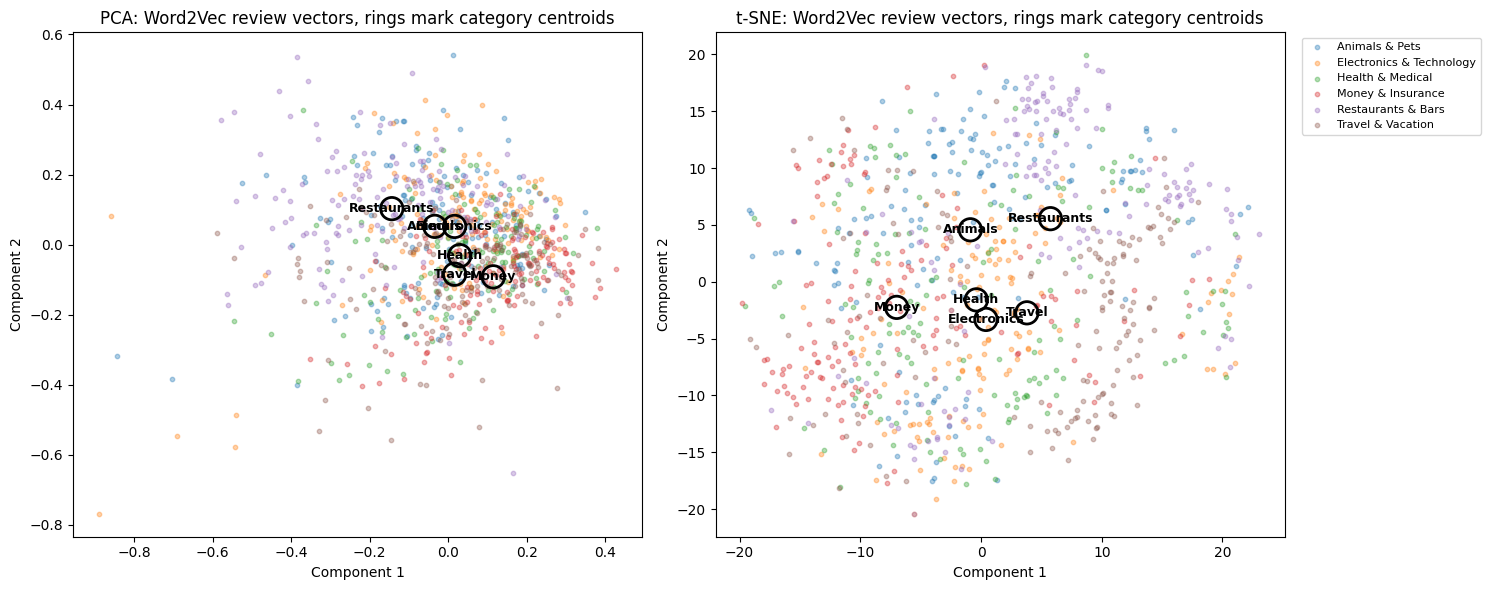

Projection of 900 review vectors


,Measure,Word2Vec
0,"PCA variance explained, PC1",12.2%
1,"PCA variance explained, PC2",8.8%
2,"PCA variance explained, total",21.0%
3,t-SNE spread within categories,11.0
4,t-SNE spread between centroids,4.9
5,t-SNE ratio (higher = better separated),0.45


In [30]:
VIS_SAMPLE = 900
vis_df, _ = train_test_split(
    raw_df, train_size=VIS_SAMPLE, random_state=RANDOM_STATE, stratify=raw_df["Category"]
)
vis_vectors = review_vectors_all[vis_df.index.to_numpy()]

pca = PCA(n_components=2, random_state=RANDOM_STATE)
pca_2d = pca.fit_transform(vis_vectors)

tsne_2d = TSNE(n_components=2, random_state=RANDOM_STATE, perplexity=30,
               init="pca", max_iter=1000).fit_transform(vis_vectors)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for name, coords, ax in [("PCA", pca_2d, axes[0]), ("t-SNE", tsne_2d, axes[1])]:
    for cat in sorted(vis_df["Category"].unique()):
        m = vis_df["Category"].values == cat
        ax.scatter(coords[m, 0], coords[m, 1], label=cat, alpha=0.35, s=10)
        ax.scatter(coords[m, 0].mean(), coords[m, 1].mean(), s=260, marker="o",
                   facecolors="none", edgecolors="black", linewidths=2, zorder=5)
        ax.annotate(cat.split(" & ")[0], (coords[m, 0].mean(), coords[m, 1].mean()),
                    fontsize=9, fontweight="bold", ha="center", va="center", zorder=6)
    ax.set_title(f"{name}: Word2Vec review vectors, rings mark category centroids")
    ax.set_xlabel("Component 1"); ax.set_ylabel("Component 2")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

centroids = np.vstack([tsne_2d[vis_df["Category"].values == c].mean(axis=0)
                       for c in sorted(vis_df["Category"].unique())])
tsne_within = np.mean([np.linalg.norm(tsne_2d[vis_df["Category"].values == c] -
                                 tsne_2d[vis_df["Category"].values == c].mean(axis=0), axis=1).mean()
                  for c in sorted(vis_df["Category"].unique())])
tsne_between = np.linalg.norm(centroids - centroids.mean(axis=0), axis=1).mean()
display_table(pd.DataFrame({
    "Measure": ["PCA variance explained, PC1", "PCA variance explained, PC2", "PCA variance explained, total",
                "t-SNE spread within categories", "t-SNE spread between centroids",
                "t-SNE ratio (higher = better separated)"],
    "Word2Vec": [f"{pca.explained_variance_ratio_[0]:.1%}", f"{pca.explained_variance_ratio_[1]:.1%}",
                 f"{pca.explained_variance_ratio_.sum():.1%}", f"{tsne_within:.1f}",
                 f"{tsne_between:.1f}", f"{tsne_between / tsne_within:.2f}"],
}), "Projection of 900 review vectors")

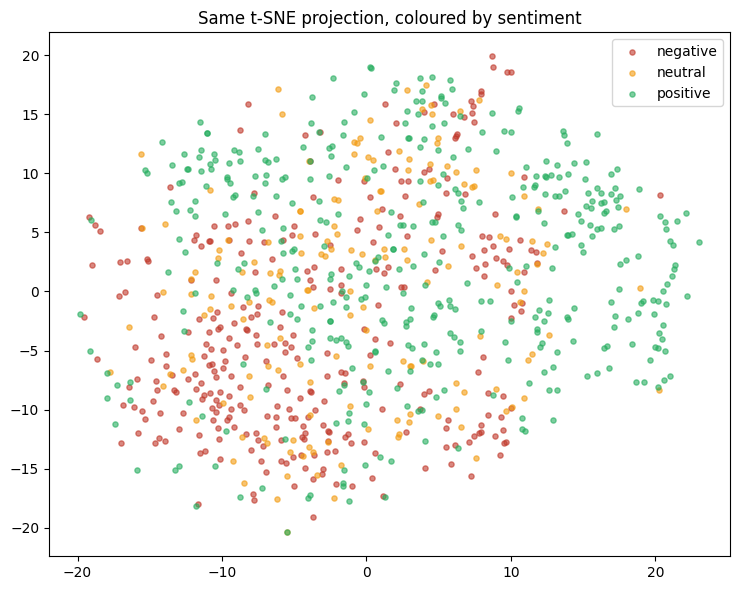

In [31]:
vis_sentiment = raw_df.loc[vis_df.index, "Stars"].apply(stars_to_sentiment)

fig, ax = plt.subplots(figsize=(7.5, 6))
for sent, colour in [("negative", "#c0392b"), ("neutral", "#f39c12"), ("positive", "#27ae60")]:
    m = vis_sentiment.values == sent
    ax.scatter(tsne_2d[m, 0], tsne_2d[m, 1], label=sent, alpha=0.6, s=14, c=colour)
ax.set_title("Same t-SNE projection, coloured by sentiment")
ax.legend()
plt.tight_layout()
plt.show()

### Interpretation

**Category shows weak structure.** PCA gives one overlapping cloud (PC1 and PC2 explain a small share of the variance) and t-SNE shows loose regions but no discrete clusters. **Sentiment is clearer:** the same t-SNE coloured by sentiment shows a gradient from negative (lower left) to positive (upper right), so averaged vectors encode tone more than topic. Averaging gives frequent evaluative words the most weight.


## E. Retrieval

**Retrieval demo.** We embed a free-text query the same way and return the three most similar reviews from all 20,400.


In [32]:
def retrieve_similar(query_text, corpus_vectors, corpus_df, model, top_k=3):
    query_vec = review_vector(query_text, model).reshape(1, -1)
    sims = cosine_similarity(query_vec, corpus_vectors)[0]
    idx = sims.argsort()[::-1][:top_k]
    out = corpus_df.iloc[idx][["Review", "Category", "Stars"]].copy()
    out["similarity"] = sims[idx].round(3)
    return out

QUERIES = [
    "my flight was cancelled and nobody refunded me",
    "the vet was expensive and my dog was not treated properly",
    "they took the money from my account without permission",
]

for q in QUERIES:
    print("=" * 100)
    print(f"QUERY: {q}")
    display(retrieve_similar(q, review_vectors_all, raw_df, word2vec_model))

QUERY: my flight was cancelled and nobody refunded me


,Review,Category,Stars,similarity
20093,The airline cancelled my (direct) flight 18 hours before departure; they instead offered a flight with a stop that would arrive 12 hours later (ridiculous s...,Travel & Vacation,1,0.909
11098,"My flight schedule changed and I never received a notification from Alternative Airlines, although they said that they emailed me. I never formally accepted...",Travel & Vacation,3,0.908
3074,"The booking process was simply but... My flight was cancelled by BA less than 24 hours before the flight and therefore, I would be due a full refund. This w...",Travel & Vacation,2,0.906


QUERY: the vet was expensive and my dog was not treated properly


,Review,Category,Stars,similarity
11299,"The polish male vet is absolutely fantastic, but the Asian short vet is not very professional and miss diagnosed my dogs illness. But the polish vet sorted ...",Animals & Pets,4,0.928
18113,"The vet arrived half an hour early, so we were not prepared mentally for our dog to go at that time. When the vet arrived our dog Lily got up to greet her a...",Animals & Pets,2,0.924
13470,My dog had difficulty breathing as earlier that week my dog was diagnosed with pneumonia. It was early evening so I called and was directed to Vets Now.The ...,Animals & Pets,2,0.920


QUERY: they took the money from my account without permission


,Review,Category,Stars,similarity
10328,"I make deposit $2700 to my own account, they ask for my bank statement. after I send them the transfer screenshot and my bank account details. they still d...",Money & Insurance,1,0.917
11653,"You paid the money into the wrong account, you stated it will go into my main account but decided to pay the money into my joint account without any warning.",Money & Insurance,2,0.915
8789,"paid my car finance off with a gift of my father, now they are holding my money till the get bank statements of my dad, i have told them to to just transfer...",Money & Insurance,1,0.912


**Measuring retrieval.** For 1,000 held-out test reviews we search the training reviews and score how often the retrieved reviews share the query's category (chance is 1/6).


In [33]:
index_cats = raw_df["Category"].to_numpy()[index_idx]
query_cats = raw_df["Category"].to_numpy()[query_idx]

def precision_at_k(query_vecs, index_vecs, k=3):
    sims = normalize(query_vecs) @ normalize(index_vecs).T
    top = np.argsort(-sims, axis=1)[:, :k]
    return (index_cats[top] == query_cats[:, None]).mean()

chance = 1 / raw_df["Category"].nunique()
display_table(pd.DataFrame([{
    "Precision@k": f"@{k}",
    "Word2Vec": f"{precision_at_k(review_vectors_all[query_idx], review_vectors_all[index_idx], k=k):.4f}",
    "Random baseline": f"{chance:.4f}",
} for k in (1, 3)]), "Retrieval on 1,000 held-out queries")

Retrieval on 1,000 held-out queries


,Precision@k,Word2Vec,Random baseline
0,@1,0.5620,0.1667
1,@3,0.5593,0.1667


With six balanced categories a random pick shares the query's category 1 time in 6, so precision well above that means the vectors carry category information. Same category is only a proxy for a useful result: a billing complaint from another sector would count as a miss.


### Interpretation

**Retrieval returns relevant reviews.** All hits for the three queries come from the implied category, though category was never part of the query. All similarities sit in a narrow band, close to the average for two unrelated reviews, so only the ranking is informative, not the score. Similarity matches subject, not outcome: the vet query's top hit is a positive review.


## F. Word2Vec vs a pretrained sentence encoder

**Pretrained comparison.** We compare Word2Vec with `all-MiniLM-L6-v2`, a sentence encoder that reads whole reviews and can represent word order.


In [34]:
t0 = time.time()
st_model = SentenceTransformer("all-MiniLM-L6-v2", device="cuda" if torch.cuda.is_available() else "cpu")
st_vectors = st_model.encode(raw_df["Review"].tolist(), batch_size=128,
                             show_progress_bar=False, convert_to_numpy=True)
print(f"Encoded {len(st_vectors):,} reviews in {time.time() - t0:.0f}s -> shape {st_vectors.shape}")

def mean_sim_st(cat_a, cat_b, n=120):
    ia = rng.choice(raw_df.index[raw_df["Category"] == cat_a], n, replace=False)
    ib = rng.choice(raw_df.index[raw_df["Category"] == cat_b], n, replace=False)
    return cosine_similarity(st_vectors[ia], st_vectors[ib]).mean()

st_within = np.mean([mean_sim_st(c, c) for c in cats])
st_between = np.mean([mean_sim_st(a, b) for a in cats for b in cats if a != b])

display(pd.DataFrame({
    "Approach": ["Word2Vec (self-trained, averaged)", "MiniLM (pretrained sentence encoder)"],
    "Dimensions": [word2vec_model.vector_size, st_vectors.shape[1]],
    "Within-category similarity": [f"{within:.3f}", f"{st_within:.3f}"],
    "Between-category similarity": [f"{between:.3f}", f"{st_between:.3f}"],
    "Separation": [f"{within - between:+.3f}", f"{st_within - st_between:+.3f}"],
}))

Encoded 20,400 reviews in 26s -> shape (20400, 384)


,Approach,Dimensions,Within-category similarity,Between-category similarity,Separation
0,"Word2Vec (self-trained, averaged)",100,0.877,0.863,+0.014
1,MiniLM (pretrained sentence encoder),384,0.219,0.158,+0.062


**Retrieval with MiniLM.** We run the same three queries as for Word2Vec.


In [35]:
def retrieve_st(query_text, top_k=3):
    sims = cosine_similarity(st_model.encode([query_text]), st_vectors)[0]
    idx = sims.argsort()[::-1][:top_k]
    out = raw_df.iloc[idx][["Review", "Category", "Stars"]].copy()
    out["similarity"] = sims[idx].round(3)
    return out

for q in QUERIES:
    print("=" * 100)
    print(f"QUERY (MiniLM): {q}")
    display(retrieve_st(q))

QUERY (MiniLM): my flight was cancelled and nobody refunded me


,Review,Category,Stars,similarity
1304,"I have booked and payed for my ticket, you have cancelled my flight and yet I didn’t receive my money back.You made my plans to crush that’s why I will neve...",Travel & Vacation,1,0.707
14280,Feeling good Recently I had a trouble with my flight and alternative airlines refunded my flight moneyThank you,Travel & Vacation,4,0.697
1963,My flight was cancelled at the last minute and I asked if I could receive a refund. This was flatly refused. Given I had booked it less than 24 hours previo...,Health & Medical,2,0.682


QUERY (MiniLM): the vet was expensive and my dog was not treated properly


,Review,Category,Stars,similarity
7854,"After spending 2 hours in this clinic between 11pm and 1am my pet had not been properly examined, the vet could not tell me what had happened to him or wher...",Animals & Pets,1,0.720
5364,The care our pet received was sympathetic but fantastically overpriced. They charged for 3 scans when she only had 2 and all the other costs are extremely h...,Animals & Pets,2,0.719
4221,"The vet was very nice, and of course I needed out of hours service, which comes at a premium. However, almost £300 just to a vet, before treatment seems exc...",Animals & Pets,2,0.703


QUERY (MiniLM): they took the money from my account without permission


,Review,Category,Stars,similarity
9588,Horrible service they completed ignoring your email texts no communication at all and they still owne me a money and they refused to give to me back,Health & Medical,1,0.635
8789,"paid my car finance off with a gift of my father, now they are holding my money till the get bank statements of my dad, i have told them to to just transfer...",Money & Insurance,1,0.631
18875,I've just set up an account and a friend sent me £670 she's owed me and they've blocked my account instantly. I have sent them details they've asked for. It...,Money & Insurance,2,0.629


**Opposite meanings.** Each pair differs only by a negation, so a lower similarity is better.


In [36]:
PAIRS = [
    ("the delivery was on time", "the delivery was not on time"),
    ("I would recommend this company", "I would not recommend this company"),
    ("staff were helpful", "staff were unhelpful"),
]

rows = []
for a, b in PAIRS:
    w2v_sim = cosine_similarity(review_vector(a, word2vec_model).reshape(1, -1),
                                review_vector(b, word2vec_model).reshape(1, -1))[0][0]
    st_sim = cosine_similarity(st_model.encode([a]), st_model.encode([b]))[0][0]
    rows.append({"Sentence A": a, "Sentence B": b,
                 "Word2Vec sim": f"{w2v_sim:.3f}", "MiniLM sim": f"{st_sim:.3f}"})

print("Opposite-meaning pairs - LOWER similarity is better:")
display(pd.DataFrame(rows))

Opposite-meaning pairs - LOWER similarity is better:


,Sentence A,Sentence B,Word2Vec sim,MiniLM sim
0,the delivery was on time,the delivery was not on time,0.976,0.915
1,I would recommend this company,I would not recommend this company,0.981,0.885
2,staff were helpful,staff were unhelpful,0.884,0.715


In [37]:
comparison = {"Approach": ["Word2Vec (self-trained)", "MiniLM (pretrained)"]}
for k in (1, 3):
    comparison[f"Precision@{k}"] = [
        f"{precision_at_k(vectors[query_idx], vectors[index_idx], k=k):.4f}"
        for vectors in (review_vectors_all, st_vectors)
    ]
display(pd.DataFrame(comparison))
print(f"Random baseline: {1 / raw_df['Category'].nunique():.4f}")

,Approach,Precision@1,Precision@3
0,Word2Vec (self-trained),0.5620,0.5593
1,MiniLM (pretrained),0.7690,0.7493


Random baseline: 0.1667


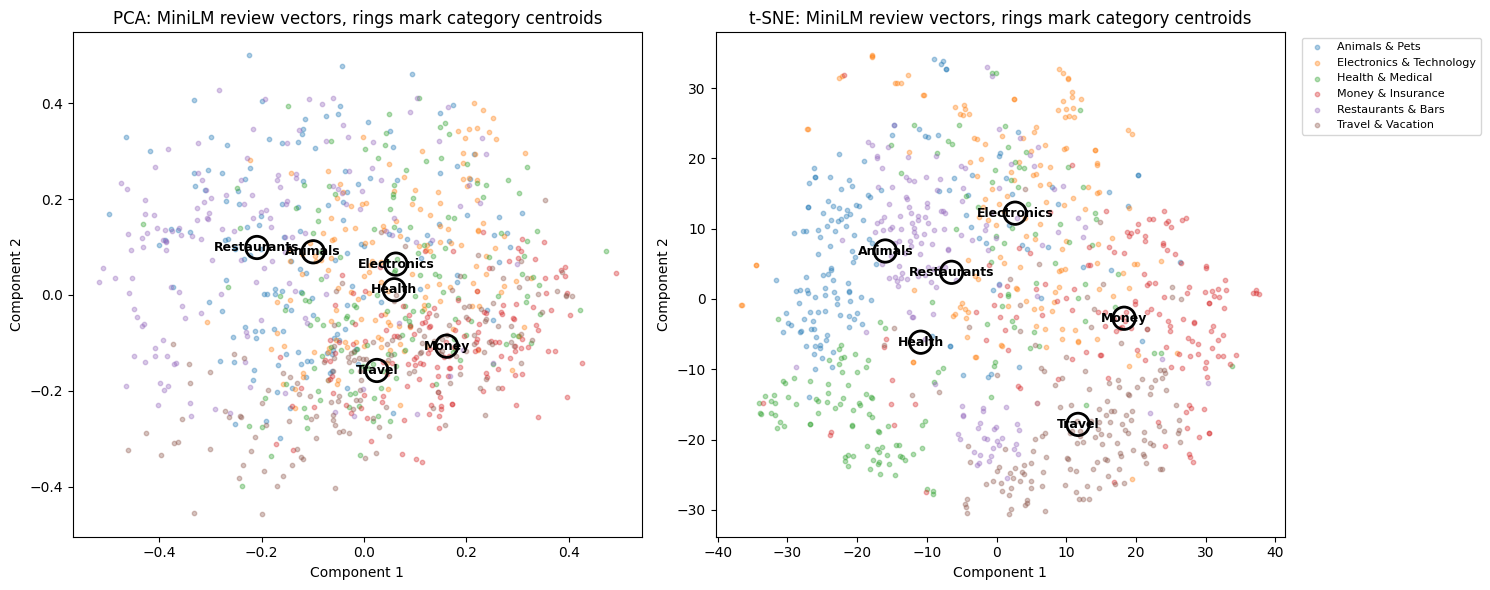

Projection of the same 900 reviews


,Approach,PCA variance explained (PC1 + PC2),t-SNE centroid ratio (higher = better separated)
0,Word2Vec,21.0%,0.45
1,MiniLM,9.2%,1.00


In [38]:
st_vis = st_vectors[vis_df.index.to_numpy()]
st_pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(st_vis)
st_pca_2d = st_pca.transform(st_vis)
st_tsne_2d = TSNE(n_components=2, random_state=RANDOM_STATE, perplexity=30,
                  init="pca", max_iter=1000).fit_transform(st_vis)

def centroid_ratio(coords):
    names = sorted(vis_df["Category"].unique())
    groups = [coords[vis_df["Category"].values == c] for c in names]
    centroids = np.vstack([g.mean(axis=0) for g in groups])
    within = np.mean([np.linalg.norm(g - g.mean(axis=0), axis=1).mean() for g in groups])
    between = np.linalg.norm(centroids - centroids.mean(axis=0), axis=1).mean()
    return between / within

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for name, coords, ax in [("PCA", st_pca_2d, axes[0]), ("t-SNE", st_tsne_2d, axes[1])]:
    for cat in sorted(vis_df["Category"].unique()):
        m = vis_df["Category"].values == cat
        ax.scatter(coords[m, 0], coords[m, 1], label=cat, alpha=0.35, s=10)
        ax.scatter(coords[m, 0].mean(), coords[m, 1].mean(), s=260, marker="o",
                   facecolors="none", edgecolors="black", linewidths=2, zorder=5)
        ax.annotate(cat.split(" & ")[0], (coords[m, 0].mean(), coords[m, 1].mean()),
                    fontsize=9, fontweight="bold", ha="center", va="center", zorder=6)
    ax.set_title(f"{name}: MiniLM review vectors, rings mark category centroids")
    ax.set_xlabel("Component 1"); ax.set_ylabel("Component 2")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

display_table(pd.DataFrame({
    "Approach": ["Word2Vec", "MiniLM"],
    "PCA variance explained (PC1 + PC2)": [f"{pca.explained_variance_ratio_.sum():.1%}",
                                           f"{st_pca.explained_variance_ratio_.sum():.1%}"],
    "t-SNE centroid ratio (higher = better separated)": [f"{centroid_ratio(tsne_2d):.2f}",
                                                         f"{centroid_ratio(st_tsne_2d):.2f}"],
}), "Projection of the same 900 reviews")

### Which approach?

**Word2Vec stays as the main method:** its vocabulary gives coherent neighbourhoods, including British terms such as `despatch` and `dpd`. **MiniLM is better at review level:** precision@1, precision@3 and category separation are all higher than for Word2Vec. Neither handles negation: "would recommend" and "would not recommend" score as near-identical in both, though less so with MiniLM.


## Limitations

Averaging discards word order, so a resolved positive case can be returned for an angry one. Absolute similarity is uninformative, so only ranking counts. The Word2Vec space encodes tone more than topic, the corpus is small for Word2Vec, and the labels are Trustpilot's sector tags rather than annotations of each review.


---

# Task 4 — Fine-Tuning a Transformer for Feedback Classification


## A. Model and configuration

**DistilBERT.** We fine-tune `distilbert-base-uncased` for 3 epochs with batch size 16, learning rate 5e-5, 6% warmup and a 512-token limit, on 5,000 training and 1,000 validation reviews. The hyperparameters were chosen on validation data in a separate search, described in the report.


In [39]:
MODEL_NAME = "distilbert-base-uncased"
MAX_LENGTH = 512
TRAIN_SAMPLE_SIZE = 5000
VAL_SAMPLE_SIZE = 1000
EPOCHS = 3
BATCH_SIZE = 16
EVAL_BATCH_SIZE = 64
LEARNING_RATE = 5e-5
WARMUP_RATIO = 0.06
WEIGHT_DECAY = 0.01

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(RANDOM_STATE)

print(f"Model : {MODEL_NAME}")
print("Device:", device,
      f"({torch.cuda.get_device_name(0)})" if device.type == "cuda" else "(CPU - training will be slow)")

Model : distilbert-base-uncased
Device: cuda (Tesla T4)


**Subword tokens and truncation.** DistilBERT splits text into subword pieces, so unseen words become known fragments. Reviews are cut at 512 tokens, and we count how many are affected and in which sentiment. The sequence-length warning below is harmless: lengths are counted without truncation, and training truncates at 512.


In [40]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

train_pool = raw_df.loc[X_train.index]
test_df_hf = raw_df.loc[X_test.index]

sample_df, _ = train_test_split(
    train_pool, train_size=TRAIN_SAMPLE_SIZE + VAL_SAMPLE_SIZE,
    random_state=RANDOM_STATE, stratify=train_pool["Category"],
)
train_df_hf, val_df_hf = train_test_split(
    sample_df, test_size=VAL_SAMPLE_SIZE,
    random_state=RANDOM_STATE, stratify=sample_df["Category"],
)

display_table(pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Reviews": [f"{len(train_df_hf):,}", f"{len(val_df_hf):,}", f"{len(test_df_hf):,}"],
    "Use": [f"Fine-tuning (sampled from Task 2's {len(train_pool):,} training rows)",
            "Best-epoch selection only",
            "Same rows as Task 2, untouched during training"],
}), "Data splits")

tok_lens = [len(tokenizer(t)["input_ids"]) for t in raw_df["Review"]]
tok_lens = pd.Series(tok_lens, index=raw_df.index)
truncated = tok_lens > MAX_LENGTH
display_table(pd.DataFrame({
    "Measure": ["Median", "Mean", "95th percentile", "Maximum", f"Reviews over {MAX_LENGTH} tokens"],
    "Subword tokens": [f"{tok_lens.median():.0f}", f"{tok_lens.mean():.0f}", f"{tok_lens.quantile(0.95):.0f}",
                       f"{tok_lens.max()}", f"{truncated.sum():,} ({100 * truncated.mean():.2f}%)"],
}), "Subword token length")
display_table(truncated.groupby(raw_df["Stars"].apply(stars_to_sentiment)).mean().mul(100).round(2).to_frame("% truncated"),
              "Truncation rate by sentiment")

Data splits


,Split,Reviews,Use
0,Train,"5,000","Fine-tuning (sampled from Task 2's 16,320 training rows)"
1,Validation,"1,000",Best-epoch selection only
2,Test,"4,080","Same rows as Task 2, untouched during training"


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (659 > 512). Running this sequence through the model will result in indexing errors


Subword token length


,Measure,Subword tokens
0,Median,66
1,Mean,84
2,95th percentile,204
3,Maximum,2346
4,Reviews over 512 tokens,81 (0.40%)


Truncation rate by sentiment


,% truncated
Stars,
negative,0.88
neutral,0.37
positive,0.03


Some reviews are truncated at 512 tokens, and the share is far higher for negative reviews than for positive ones, so truncation hits unhappy customers hardest.


In [41]:
class ReviewDataset(Dataset):

    def __init__(self, texts, labels, label_to_id):
        self.texts = list(texts)
        self.label_ids = [label_to_id[l] for l in labels]

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, i):
        return self.texts[i], self.label_ids[i]

def collate_batch(batch):
    texts, labels = zip(*batch)
    enc = tokenizer(list(texts), truncation=True, padding=True,
                    max_length=MAX_LENGTH, return_tensors="pt")
    return enc["input_ids"], enc["attention_mask"], torch.tensor(labels)

def encode_dataset(texts, labels, label_to_id) -> ReviewDataset:
    return ReviewDataset(texts, labels, label_to_id)

sample_review = train_df_hf["Review"].iloc[0]
print("Original text  :", sample_review[:120], "...")
print("NLTK words     :", tokenize_nltk(sample_review, remove_stopwords=False)[:14])
print("DistilBERT     :", tokenizer.tokenize(sample_review)[:18])

Original text  : DPD not allowed to leave package in designated safe place may be a deal breaker for placing further online orders with L ...
NLTK words     : ['dpd', 'not', 'allowed', 'to', 'leave', 'package', 'in', 'designated', 'safe', 'place', 'may', 'be', 'a', 'deal']
DistilBERT     : ['d', '##pd', 'not', 'allowed', 'to', 'leave', 'package', 'in', 'designated', 'safe', 'place', 'may', 'be', 'a', 'deal', 'breaker', 'for', 'placing']


The `##` marks a piece that continues the previous one, so a word the model has never seen is split into known fragments (here `dpd` becomes `d`, `##pd`).


## C. Fine-tuning

**Training.** We keep the pretrained body, add a new classification head and update all weights, padding per batch. The learning rate warms up then decays linearly, and we keep the epoch with the best validation macro F1; the test set plays no part. The same helper fine-tunes DistilBERT for each target.


In [42]:
def predict(model, dataset, batch_size=EVAL_BATCH_SIZE):
    loader = DataLoader(dataset, batch_size=batch_size, collate_fn=collate_batch)
    model.eval()
    preds = []
    start = time.time()
    with torch.no_grad():
        for ids, mask, _ in loader:
            logits = model(input_ids=ids.to(device), attention_mask=mask.to(device)).logits
            preds.append(logits.argmax(dim=-1).cpu().numpy())
    return np.concatenate(preds), time.time() - start

def fine_tune(train_dataset, val_dataset, num_labels):
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=num_labels).to(device)
    loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                        collate_fn=collate_batch)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE,
                                  weight_decay=WEIGHT_DECAY)

    total_steps = len(loader) * EPOCHS
    scheduler = get_linear_schedule_with_warmup(
        optimizer, int(total_steps * WARMUP_RATIO), total_steps)

    val_scores = []
    best = {"macro_f1": -1.0, "epoch": 0, "state": None}
    y_val = np.array(val_dataset.label_ids)
    start = time.time()

    for epoch in range(1, EPOCHS + 1):
        model.train()
        running = 0.0
        for ids, mask, labels in loader:
            ids, mask, labels = ids.to(device), mask.to(device), labels.to(device)
            optimizer.zero_grad()
            out = model(input_ids=ids, attention_mask=mask, labels=labels)
            out.loss.backward()
            optimizer.step()
            scheduler.step()

            running += out.loss.item()

        val_pred, _ = predict(model, val_dataset)
        val_f1 = f1_score(y_val, val_pred, average="macro", zero_division=0)
        val_scores.append({"epoch": epoch, "val_macro_f1": val_f1,
                           "train_loss": running / len(loader)})
        print(f"  epoch {epoch}/{EPOCHS}  train loss {running / len(loader):.4f}  "
              f"val macro F1 {val_f1:.4f}")

        if val_f1 > best["macro_f1"]:
            best = {"macro_f1": val_f1, "epoch": epoch,
                    "state": copy.deepcopy(model.state_dict())}

    elapsed = time.time() - start
    model.load_state_dict(best["state"])
    print(f"  best epoch: {best['epoch']} (val macro F1 {best['macro_f1']:.4f})")
    return model, elapsed, pd.DataFrame(val_scores)

In [43]:
CATEGORY_LABELS = sorted(raw_df["Category"].unique())
cat_to_id = {name: i for i, name in enumerate(CATEGORY_LABELS)}

cat_train_ds = encode_dataset(train_df_hf["Review"], train_df_hf["Category"], cat_to_id)
cat_val_ds = encode_dataset(val_df_hf["Review"], val_df_hf["Category"], cat_to_id)
cat_test_ds = encode_dataset(test_df_hf["Review"], test_df_hf["Category"], cat_to_id)

print("Fine-tuning DistilBERT (category)...")
cat_model, cat_train_time, cat_val_scores = fine_tune(
    cat_train_ds, cat_val_ds, num_labels=len(CATEGORY_LABELS))
print(f"Training time: {cat_train_time:.1f}s on {device.type}")
display_table(cat_val_scores.round(4), "Per-epoch results (DistilBERT, category)")

Fine-tuning DistilBERT (category)...


[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1/3  train loss 0.8880  val macro F1 0.7867
  epoch 2/3  train loss 0.3964  val macro F1 0.7885
  epoch 3/3  train loss 0.2348  val macro F1 0.7912
  best epoch: 3 (val macro F1 0.7912)
Training time: 387.4s on cuda
Per-epoch results (DistilBERT, category)


,epoch,val_macro_f1,train_loss
0,1,0.7867,0.8880
1,2,0.7885,0.3964
2,3,0.7912,0.2348


## D. Evaluation: category

We score DistilBERT (category) on the same 4,080 test reviews as Task 2; the output gives accuracy, macro F1 and per-class scores.


In [44]:
cat_pred_ids, cat_infer_time = predict(cat_model, cat_test_ds)
cat_true_ids = np.array([cat_to_id[l] for l in test_df_hf["Category"]])

transformer_accuracy = accuracy_score(cat_true_ids, cat_pred_ids)
transformer_macro_f1 = f1_score(cat_true_ids, cat_pred_ids, average="macro", zero_division=0)
transformer_weighted_f1 = f1_score(cat_true_ids, cat_pred_ids, average="weighted", zero_division=0)

report_tables(np.array(CATEGORY_LABELS)[cat_true_ids], np.array(CATEGORY_LABELS)[cat_pred_ids],
              CATEGORY_LABELS, "DistilBERT (category)")

DistilBERT (category): test-set metrics


,Accuracy,Macro precision,Macro recall,Macro F1,Weighted F1,Test reviews
0,0.8213,0.8227,0.8213,0.8214,0.8214,"4,080"


DistilBERT (category): per-class results


,Class,precision,recall,f1-score,support
0,Animals & Pets,0.8560,0.7603,0.8053,680
1,Electronics & Technology,0.7550,0.7794,0.7670,680
2,Health & Medical,0.7635,0.7882,0.7757,680
3,Money & Insurance,0.8307,0.8588,0.8445,680
4,Restaurants & Bars,0.8256,0.8426,0.8341,680
5,Travel & Vacation,0.9052,0.8985,0.9018,680


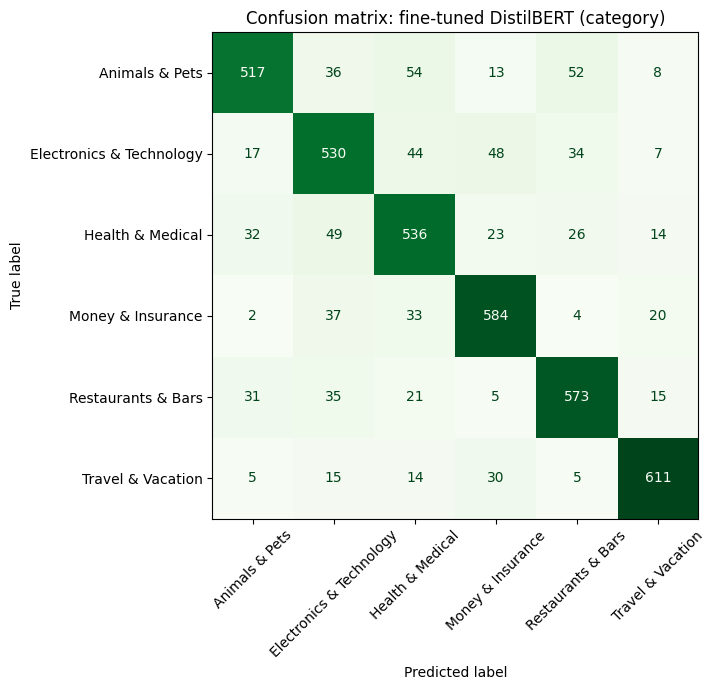

In [45]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(cat_true_ids, cat_pred_ids),
    display_labels=CATEGORY_LABELS).plot(ax=ax, cmap="Greens", xticks_rotation=45, colorbar=False)
plt.title("Confusion matrix: fine-tuned DistilBERT (category)")
plt.tight_layout()
plt.show()

## E. Sentiment classification

We fine-tune the same architecture on the three-class sentiment target (negative, neutral, positive) and compare it with the classical sentiment model from Task 2.


Fine-tuning DistilBERT (sentiment)...


[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1/3  train loss 0.6637  val macro F1 0.6616
  epoch 2/3  train loss 0.4173  val macro F1 0.7029
  epoch 3/3  train loss 0.2449  val macro F1 0.7105
  best epoch: 3 (val macro F1 0.7105)
Training time: 408.7s
Per-epoch results (DistilBERT, sentiment)


,epoch,val_macro_f1,train_loss
0,1,0.6616,0.6637
1,2,0.7029,0.4173
2,3,0.7105,0.2449


DistilBERT (sentiment): test-set metrics


,Accuracy,Macro precision,Macro recall,Macro F1,Weighted F1,Test reviews
0,0.7640,0.7056,0.7080,0.7046,0.7713,"4,080"


DistilBERT (sentiment): per-class results


,Class,precision,recall,f1-score,support
0,negative,0.8121,0.7458,0.7775,1420
1,neutral,0.4110,0.5085,0.4545,708
2,positive,0.8937,0.8699,0.8816,1952


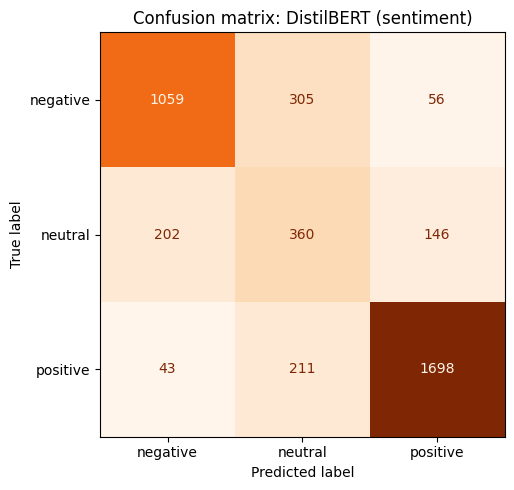

In [46]:
SENTIMENT_LABELS = ["negative", "neutral", "positive"]
sent_to_id = {name: i for i, name in enumerate(SENTIMENT_LABELS)}

train_sent = train_df_hf["Stars"].apply(stars_to_sentiment)
test_sent = test_df_hf["Stars"].apply(stars_to_sentiment)

val_sent = val_df_hf["Stars"].apply(stars_to_sentiment)

sent_train_ds = encode_dataset(train_df_hf["Review"], train_sent, sent_to_id)
sent_val_ds = encode_dataset(val_df_hf["Review"], val_sent, sent_to_id)
sent_test_ds = encode_dataset(test_df_hf["Review"], test_sent, sent_to_id)

print("Fine-tuning DistilBERT (sentiment)...")
sent_model, sent_train_time, sent_val_scores = fine_tune(
    sent_train_ds, sent_val_ds, num_labels=len(SENTIMENT_LABELS))
print(f"Training time: {sent_train_time:.1f}s")
display_table(sent_val_scores.round(4), "Per-epoch results (DistilBERT, sentiment)")

sent_pred_ids, sent_infer_time = predict(sent_model, sent_test_ds)
sent_true_ids = np.array([sent_to_id[l] for l in test_sent])

transformer_sent_accuracy = accuracy_score(sent_true_ids, sent_pred_ids)
transformer_sent_macro_f1 = f1_score(sent_true_ids, sent_pred_ids, average="macro", zero_division=0)

report_tables(np.array(SENTIMENT_LABELS)[sent_true_ids], np.array(SENTIMENT_LABELS)[sent_pred_ids],
              SENTIMENT_LABELS, "DistilBERT (sentiment)")

fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(sent_true_ids, sent_pred_ids),
    display_labels=SENTIMENT_LABELS).plot(ax=ax, cmap="Oranges", colorbar=False)
plt.title("Confusion matrix: DistilBERT (sentiment)")
plt.tight_layout()
plt.show()

### Neutral class

Neutral F1 and recall rise above Task 2's, but neutral is still the weakest class. Many 3-star reviews mix praise and complaint, so the label is a rating midpoint, not a property of the text.


## F. Comparison with the classical baseline

We compare DistilBERT with the Linear SVM chosen in Task 2 on accuracy, speed, size and hardware. One caveat favours the SVM: DistilBERT saw 5,000 training reviews, under a third of the SVM's 16,320.


In [47]:
clf_step = best_baseline["pipeline"].named_steps["clf"]
svm_params = clf_step.coef_.size + clf_step.intercept_.size
transformer_params = sum(p.numel() for p in cat_model.parameters())
peak_vram = torch.cuda.max_memory_allocated() / 1e9 if device.type == "cuda" else float("nan")

comparison = pd.DataFrame({
    "Dimension": [
        "Accuracy (category)",
        "Macro F1 (category)",
        "Macro F1 (sentiment)",
        "Training examples used",
        "Training time",
        "Inference time (4,080 reviews)",
        "Throughput (reviews/sec)",
        "Learned parameters",
        "Hardware",
    ],
    f"{best_name} (Task 2)": [
        f"{best_baseline['accuracy']:.4f}",
        f"{best_baseline['macro_f1']:.4f}",
        f"{sentiment_macro_f1:.4f}",
        f"{len(X_train):,}",
        f"{best_baseline['train_time']:.1f}s",
        f"{best_baseline['infer_time']:.2f}s",
        f"{len(X_test) / best_baseline['infer_time']:,.0f}",
        f"{svm_params:,}",
        "CPU",
    ],
    "DistilBERT (Task 4)": [
        f"{transformer_accuracy:.4f}",
        f"{transformer_macro_f1:.4f}",
        f"{transformer_sent_macro_f1:.4f}",
        f"{len(train_df_hf):,}",
        f"{cat_train_time:.1f}s",
        f"{cat_infer_time:.1f}s",
        f"{len(test_df_hf) / cat_infer_time:,.0f}",
        f"{transformer_params:,}",
        device.type.upper(),
    ],
})
display(comparison)

ratios = [
    ("Training time", f"{cat_train_time / best_baseline['train_time']:.0f}x slower"),
    ("Inference time", f"{cat_infer_time / best_baseline['infer_time']:.0f}x slower"),
    ("Learned parameters", f"{transformer_params / svm_params:.0f}x more"),
]
if device.type == "cuda":
    ratios.append(("Peak GPU memory", f"{peak_vram:.2f} GB"))
display_table(pd.DataFrame(ratios, columns=["DistilBERT against the Linear SVM", "Ratio"]), "Cost ratios")

,Dimension,Linear SVM (Task 2),DistilBERT (Task 4)
0,Accuracy (category),0.8260,0.8213
1,Macro F1 (category),0.8258,0.8214
2,Macro F1 (sentiment),0.6359,0.7046
3,Training examples used,"16,320","5,000"
4,Training time,8.1s,387.4s
5,"Inference time (4,080 reviews)",0.94s,52.2s
6,Throughput (reviews/sec),"4,352",78
7,Learned parameters,"603,990","66,958,086"
8,Hardware,CPU,CUDA


Cost ratios


,DistilBERT against the Linear SVM,Ratio
0,Training time,48x slower
1,Inference time,56x slower
2,Learned parameters,111x more
3,Peak GPU memory,4.48 GB


In [48]:
svm_pred = best_baseline["pipeline"].predict(X_test)
transformer_pred_labels = np.array(CATEGORY_LABELS)[cat_pred_ids]
truth = test_df_hf["Category"].values

disagree = svm_pred != transformer_pred_labels
svm_right = (svm_pred == truth) & disagree
tr_right = (transformer_pred_labels == truth) & disagree
both_wrong = (svm_pred != truth) & (transformer_pred_labels != truth) & disagree

display_table(pd.DataFrame({
    "Outcome": ["Same prediction", "Different predictions", "  Linear SVM correct, DistilBERT wrong",
                "  DistilBERT correct, Linear SVM wrong", "  Both wrong, with different answers"],
    "Reviews": [f"{(~disagree).sum():,}", f"{disagree.sum():,}", f"{svm_right.sum():,}",
                f"{tr_right.sum():,}", f"{both_wrong.sum():,}"],
    "Share of test set": [f"{100 * m.mean():.1f}%" for m in
                          (~disagree, disagree, svm_right, tr_right, both_wrong)],
}), "Agreement between the two category models")

Agreement between the two category models


,Outcome,Reviews,Share of test set
0,Same prediction,"3,304",81.0%
1,Different predictions,776,19.0%
2,"Linear SVM correct, DistilBERT wrong",289,7.1%
3,"DistilBERT correct, Linear SVM wrong",270,6.6%
4,"Both wrong, with different answers",217,5.3%


### Discussion

**Where each wins.** The SVM scores as well or better on category, where vocabulary is enough; the transformer helps on sentiment, where clause structure matters. The SVM is far cheaper and its coefficients can be read directly. Where the two disagree, the counts above show how often each is right; their errors differ, so an ensemble could help.


## Practical implications

**Truncation bias.** A 512-token limit removes more text from negative reviews than positive ones, which neither the loss nor the accuracy would show. **Reproducibility.** GPU training is not exactly reproducible, so transformer figures are approximate.


---

# Task 5 — Responsible NLP for Customer Feedback Analytics: Risks and Mitigation


## A. Quantifying the risks

We measure four risks directly on the models we built.


### A1. Urgent complaints missed

How many 1-star and 2-star test reviews each sentiment model calls positive.


In [49]:
test_stars = test_df_hf["Stars"].values
sent_pred_labels = np.array(SENTIMENT_LABELS)[sent_pred_ids]

classical_sent_pred = sentiment_clf.predict(Xs_test)

rows = []
for star in [1, 2]:
    mask = test_stars == star
    rows.append({
        "True rating": f"{star} star",
        "Reviews in test set": int(mask.sum()),
        "Classical -> positive": int((classical_sent_pred[mask] == "positive").sum()),
        "DistilBERT -> positive": int((sent_pred_labels[mask] == "positive").sum()),
    })
urgent = pd.DataFrame(rows)
urgent["Classical miss rate"] = (urgent["Classical -> positive"] / urgent["Reviews in test set"] * 100).round(2).astype(str) + "%"
urgent["DistilBERT miss rate"] = (urgent["DistilBERT -> positive"] / urgent["Reviews in test set"] * 100).round(2).astype(str) + "%"
display_table(urgent, "Urgent complaints called positive")

one_star = test_stars == 1
missed = one_star & (sent_pred_labels == "positive")
print(f"1-star reviews called POSITIVE by DistilBERT: {missed.sum()} of {one_star.sum()}")
if missed.sum():
    print("\nExamples of the most severe errors:")
    for txt in test_df_hf.loc[missed, "Review"].head(3):
        print(f"  - {txt[:170]}")

Urgent complaints called positive


,True rating,Reviews in test set,Classical -> positive,DistilBERT -> positive,Classical miss rate,DistilBERT miss rate
0,1 star,783,42,23,5.36%,2.94%
1,2 star,637,74,33,11.62%,5.18%


1-star reviews called POSITIVE by DistilBERT: 23 of 783

Examples of the most severe errors:
  - Alison in the Aylesbury Travelodge was outstanding. Absolutely lovely, personable and attentive. First Class face-to-face customer services. 5 Stars...Where it went wrong
  - Half way through my application I had a change of mind and decided not to follow through with the IVA ,30 plus calls in a matter of days from these guys  , The staff are 
  - Purchased the more expensive test as it stated someone would carry out the Pcr test and when we arrived we had to do it ourselves, so could have brought an at home kit.


### A2. Unfair treatment across groups

The dataset has no demographic fields, so we use the six business sectors as groups and compare error rates across them.


In [50]:
cat_pred_labels = np.array(CATEGORY_LABELS)[cat_pred_ids]
sent_true_labels = np.array(SENTIMENT_LABELS)[sent_true_ids]

fairness = []
for cat in sorted(raw_df["Category"].unique()):
    m = test_df_hf["Category"].values == cat
    fairness.append({
        "Category": cat,
        "Test reviews": int(m.sum()),
        "Category error rate": f"{100 * (cat_pred_labels[m] != test_df_hf['Category'].values[m]).mean():.1f}%",
        "Sentiment error rate": f"{100 * (sent_pred_labels[m] != sent_true_labels[m]).mean():.1f}%",
        "Negative recall": f"{(sent_pred_labels[m][sent_true_labels[m] == 'negative'] == 'negative').mean():.2f}",
    })
fairness_df = pd.DataFrame(fairness)
display_table(fairness_df, "Error rates by sector")

sent_errs = [float(r["Sentiment error rate"].rstrip("%")) for r in fairness]
neg_rec = [float(r["Negative recall"]) for r in fairness]
cat_errs = [float(r["Category error rate"].rstrip("%")) for r in fairness]
display_table(pd.DataFrame({
    "Measure": ["Category error rate", "Sentiment error rate", "Negative recall"],
    "Lowest sector": [f"{min(cat_errs):.1f}%", f"{min(sent_errs):.1f}%", f"{min(neg_rec):.2f}"],
    "Highest sector": [f"{max(cat_errs):.1f}%", f"{max(sent_errs):.1f}%", f"{max(neg_rec):.2f}"],
}), "Spread across sectors")

Error rates by sector


,Category,Test reviews,Category error rate,Sentiment error rate,Negative recall
0,Animals & Pets,680,24.0%,21.8%,0.74
1,Electronics & Technology,680,22.1%,26.5%,0.76
2,Health & Medical,680,21.2%,21.6%,0.76
3,Money & Insurance,680,14.1%,26.5%,0.72
4,Restaurants & Bars,680,15.7%,20.0%,0.73
5,Travel & Vacation,680,10.1%,25.3%,0.76


Spread across sectors


,Measure,Lowest sector,Highest sector
0,Category error rate,10.1%,24.0%
1,Sentiment error rate,20.0%,26.5%
2,Negative recall,0.72,0.76


We reuse the NER output as a privacy audit.


In [51]:
pii_types = ["PERSON", "ORG", "GPE", "MONEY", "DATE"]
pii = entities_df[entities_df["entity_label"].isin(pii_types)]

summary = (pii.groupby("entity_label")
             .agg(occurrences=("entity_text", "size"), unique_values=("entity_text", "nunique"))
             .reindex(pii_types))
summary["reviews_affected"] = [pii[pii["entity_label"] == t]["review_id"].nunique() for t in pii_types]
summary["% of sample"] = (summary["reviews_affected"] / len(working_df) * 100).round(1)
display_table(summary, "Personal and sensitive entity types")

full_corpus_people = (ner_features["PERSON"] > 0).mean()
person_rows = pii[pii["entity_label"] == "PERSON"]
display_table(pd.DataFrame({
    "Measure": [f"Reviews naming a person, all {len(ner_features):,} reviews",
                f"Reviews naming a person, {len(working_df):,}-review sample",
                "Distinct personal names in the sample"],
    "Value": [f"{100 * full_corpus_people:.1f}%",
              f"{100 * person_rows['review_id'].nunique() / len(working_df):.1f}%",
              f"{person_rows['entity_text'].nunique()}"],
}), "People named in the reviews")
top_people = person_rows["entity_text"].value_counts().head(8)
display_table(top_people.rename_axis("Tagged name").reset_index(name="Mentions"), "Most frequently tagged names")

Personal and sensitive entity types


,occurrences,unique_values,reviews_affected,% of sample
entity_label,,,,
PERSON,1114,745,751,25.0
ORG,1266,870,838,27.9
GPE,484,278,342,11.4
MONEY,344,210,241,8.0
DATE,2015,906,1126,37.5


People named in the reviews


,Measure,Value
0,"Reviews naming a person, all 20,400 reviews",25.0%
1,"Reviews naming a person, 3,000-review sample",25.0%
2,Distinct personal names in the sample,745


Most frequently tagged names


,Tagged name,Mentions
0,Xmas,22
1,Evri,12
2,George,10
3,Chris,8
4,Covid,8
5,Peter Tyson,7
6,Steve,7
7,James,7


Many reviews name at least one person. NER is imperfect: `Xmas`, `Evri` and `Covid` are among the most frequently tagged names but are not people.


### A4. Over-reliance

We check whether the transformer's confidence separates correct from wrong predictions, and how often it disagrees with the SVM.


In [52]:
cat_loader = DataLoader(cat_test_ds, batch_size=64, collate_fn=collate_batch)
cat_model.eval()
probs = []
with torch.no_grad():
    for ids, mask, _ in cat_loader:
        logits = cat_model(input_ids=ids.to(device), attention_mask=mask.to(device)).logits
        probs.append(torch.softmax(logits, dim=-1).max(dim=-1).values.cpu().numpy())
confidence = np.concatenate(probs)
correct = cat_pred_ids == cat_true_ids

display_table(pd.DataFrame({
    "Predictions": ["Correct", "Wrong"],
    "Count": [f"{correct.sum():,}", f"{(~correct).sum():,}"],
    "Mean confidence": [f"{confidence[correct].mean():.3f}", f"{confidence[~correct].mean():.3f}"],
}), "Confidence of the DistilBERT category model")
display_table(pd.DataFrame([{
    "Confidence at least": f"{thr:.0%}",
    "Predictions": f"{(confidence >= thr).sum():,}",
    "Of which wrong": f"{(~correct & (confidence >= thr)).sum():,}",
    "% wrong": f"{100 * (~correct[confidence >= thr]).mean():.1f}%",
} for thr in [0.90, 0.95, 0.99]]), "Errors among confident predictions")


Confidence of the DistilBERT category model


,Predictions,Count,Mean confidence
0,Correct,"3,351",0.938
1,Wrong,729,0.667


Errors among confident predictions


,Confidence at least,Predictions,Of which wrong,% wrong
0,90%,"3,062",177,5.8%
1,95%,"2,816",103,3.7%
2,99%,948,5,0.5%


Confidence separates correct predictions from wrong ones, but some predictions made with high confidence are still wrong. The two models disagree on a noticeable share of reviews (Task 4 table), and neither exposes that disagreement to a downstream user.


## B. What the measurements show

Some urgent complaints are classed as positive (A1). Neutral is the weakest sentiment class, so ambivalent customers are least reliably identified. Category error rates vary clearly by sector while sentiment error rates move less; this is only a weak proxy for fairness, since the brief means demographic groups and the dataset has none. Confident errors remain. Toxic content is named in the brief but not measured, because a word list would manufacture a signal.


## C. Modern trend: RAG

Task 3 built the retrieval half of a Retrieval-Augmented Generation system. Ranking works, but absolute similarity cannot be thresholded and negation is ignored. The report covers the wider assessment.


---

## Conclusion

**Category routing.** The Linear SVM matched or beat DistilBERT while training and predicting far faster (see the Task 4 table), so the transformer earned nothing here. **Sentiment.** The transformer improved macro F1, mainly by recovering part of the neutral class, which is still the weakest. **Retrieval.** Word2Vec ranks related reviews usefully but ignores negation; MiniLM is better at review level. **Risk.** Errors are measurable and uneven, so a deployment should route low-confidence predictions to people. The report gives the reasoning and recommendations.
